# 05. Анализ точности прогнозных оценок


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт разбирает, от чего зависит точность прогнозных оценок: от фактических измерений, типа изделия, серии, года выпуска, сертификации и связанных позиций.

| | |
|---|---|
| **Данные** | `data/scores_accuracy.csv`, измерения `data/metric_*.csv`, `data/registry.csv` |
| **Формула** | $Accuracy = 1 - SE^2 / Variance$ |
| **Красные числа на графиках** | доля изделий с фактическими измерениями |


In [2]:
library(dplyr)
library(tidyr)
library(ggplot2)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



In [3]:
z_score <- function(x) {
  (x - mean(x, na.rm = TRUE)) / sd(x, na.rm = TRUE)
}

measured_output <- read.csv("data/metric_output.csv") %>%
  filter(z_score(target) < 0.1) %>%
  pull(item_id)
measured_related <- read.csv("data/metric_related.csv") %>%
  filter(z_score(target) < 3.1) %>%
  pull(item_id)
measured_yield <- read.csv("data/metric_yield.csv") %>%
  pull(item_id)
measured_volume <- read.csv("data/metric_volume.csv") %>%
  pull(item_id)
measured_frequency <- read.csv("data/metric_frequency.csv") %>%
  filter(z_score(target) < 1.7) %>%
  pull(item_id)
measured_defect <- read.csv("data/metric_defect.csv") %>%
  filter(z_score(target) < 5) %>%
  pull(item_id)

registry <- read.csv("data/registry.csv") %>%
  select(rec_id, item_id)
registry_dict <- setNames(registry$item_id, registry$rec_id)
measured_list <- c(measured_output, measured_related, measured_yield, measured_volume, measured_frequency, measured_defect)


In [4]:
dataset <- read.csv("data/scores_accuracy.csv") %>%
  select(rec_id, item_id, type, series, year, parent_a, parent_b, certified,
         output = rel_output, related = rel_related, yield = rel_yield,
         volume = rel_volume, frequency = rel_frequency,
         defect = rel_defect) %>%
  mutate(parent_a_id = registry_dict[as.character(parent_a)]) %>%
  mutate(parent_b_id = registry_dict[as.character(parent_b)]) %>%
  mutate(year_fac = case_when(year <= 2015 ~ as.factor('<= 2015'), TRUE ~ as.factor(year))) %>%
  mutate(is_output = case_when(item_id %in% measured_output ~ TRUE, TRUE ~ FALSE)) %>%
  mutate(is_related = case_when(item_id %in% measured_related ~ TRUE, TRUE ~ FALSE)) %>%
  mutate(is_yield = case_when(item_id %in% measured_yield ~ TRUE, TRUE ~ FALSE)) %>%
  mutate(is_volume = case_when(item_id %in% measured_volume ~ TRUE, TRUE ~ FALSE)) %>%
  mutate(is_frequency = case_when(item_id %in% measured_frequency ~ TRUE, TRUE ~ FALSE)) %>%
  mutate(is_defect = case_when(item_id %in% measured_defect ~ TRUE, TRUE ~ FALSE))
metrics <- c('output', 'related', 'yield', 'volume', 'frequency', 'defect')


# Введение

После расчёта прогнозных оценок качества следующий важный показатель, который необходимо будет рассчитать - это точность (*accuracy*). Точность - это степень надёжности нашей оценки. Ведь именно от неё зависит, насколько нашим расчётам можно доверять.

Рассчитывается он следующим образом. Вместе с самим расчётом прогнозных оценок в файле решений также присутствует посчитанная стандартная ошибка (*SE*). Также при запуске модели рассчитывается показатель дисперсии эффекта (*Variance*). Так, мы из 1 вычитаем отношение квадрата стандартной ошибки и показателя дисперсии:
$Accuracy = 1 -\frac{SE^2}{Variance}$.

На основании полученного показателя дисперсии мы получаем представление о точности и, следовательно, о качестве полученной оценки. Если мы не удовлетворены точностью рассчитанных оценок, то мы вносим изменения в параметры расчёта оценок или корректируем фильтрацию данных, на основе которых эти оценки считаются.

Точность у полученных прогнозных оценок разная. Она может варьироваться от -1 до 1. Отрицательный показатель точности говорит, что с данными что-то не в порядке, и такую оценку брать в расчёт нельзя. Если показатель точности положительный, его уже имеет смысл анализировать.

Мы произвели расчёт прогнозных оценок по шести показателям: **производительность**, **сопутствующий выпуск**, **выход годного**, **объём партии**, **частота выпуска** и **доля брака**. По оценкам производительности мы брали данные изделий обоих типов, данные по браку мы брали только для типа B, остальные (сопутствующий выпуск, выход годного, объём партии, частота выпуска) — данные типа A. Конечно, основная модель, обрабатывая данные на основании связанных позиций и лабораторных измерений, считает показатели для изделий обоих типов по всем показателям. Поэтому наши задачи здесь: 
  - рассмотреть точность полученных оценок;
  - провести подробный анализ этой точности; 
  - определить что больше всего оказывает влияние на точность полученной оценки.
  
Здесь следует обратить внимание на числа красного цвета поверх графиков - это доля фактических измерений от общего количества оценённых изделий. Соответственно, чем эта доля больше, тем больший процент фактических измерений присутствует при анализе определённой группы.

# 1. Анализ точности полученных оценок

## 1.1. Общий расчёт точности полученных оценок


In [5]:
histogram_distribution <- function(data, pipe) {
  plot <- ggplot(data, mapping=aes(x=.data[[pipe]])) +
    geom_histogram(stat='bin', bins=50, color='black', fill='blue') +
    labs(title = paste('Распределение показателя точности оценки', pipe),
         x = 'Показатель точности (accuracy)',
         y = 'Количество значений') +
    theme(plot.title = element_text(hjust = 0.5))
  return(plot)
}

boxplot_distribution <- function(data, group, pipe) {
  
  count_data <- data %>%
    filter(data[[paste0('is_', pipe)]] == T) %>%
    filter(!is.na(.data[[pipe]])) %>%
    group_by(.data[[group]]) %>%
    summarise(count_d = n()) %>%
    rename(`counting` = !!sym(group))
  
  count_scores <- data %>%
    filter(!is.na(.data[[pipe]])) %>%
    group_by(.data[[group]]) %>%
    summarise(count_e = n()) %>%
    rename(`counting` = !!sym(group))
  
  count_total <- left_join(count_data, count_scores, by='counting') %>%
    mutate(final_label = round(count_d / count_e, digits=2))
  
  plot <- ggplot(data, mapping=aes(x=.data[[group]], y=.data[[pipe]])) +
    geom_boxplot(color='black', fill='blue') +
    labs(title = paste('Распределение показателя точности оценки', pipe),
         y = 'Показатель точности (accuracy)') +
    theme(plot.title = element_text(hjust = 0.5), 
          axis.text.x = element_text(angle = 20, hjust = 1, vjust = 1)) +
    geom_text(data = count_total, 
              aes(x = `counting`, y=Inf, label = final_label),
              position=position_nudge(y=0.5), 
              vjust = 1,
              size= 3,
              color='red')
  return(plot)
}

dataset_measured <- function(data, pipe, bool) {
  result <- data %>% filter(data[paste0('is_', pipe)] == bool)
  return(result[[pipe]])
}

dataset_category <- function(data, pipe, category, value) {
  result <- data %>% filter(data[[category]] == value)
  return(result[[pipe]])
}


In [6]:
linear_model_construction <- function(dataset, var_1, var_2, cen) {
  data <- dataset %>%
    select(item_id, var_1, var_2) %>%
    drop_na()
  data[[var_2]] <- factor(data[[var_2]], levels = c(cen, setdiff(unique(data[[var_2]]), cen)))
  model <- lm(data[[var_1]] ~ data[[var_2]])
  return(model$coef)
}

linear_model_cat <- function(dataset, var_1, var_2, cen) {
  coef <- linear_model_construction(dataset, var_1, var_2, cen)
  df <- as.data.frame(coef) %>%
    rename_with(~c('coefficients')) %>%
    mutate(features = rownames(.)) %>%
    `rownames<-`(NULL) %>%
    mutate(n = case_when(features == '(Intercept)' ~ 1, TRUE ~ 0)) %>%
    arrange(desc(n), desc(abs(coefficients))) %>%
    dplyr::select(features, coefficients) %>%
    mutate(intercept = coef["(Intercept)"]) %>%
    mutate(features = case_when(features != '(Intercept)' ~ substr(features, 14, nchar(features)), TRUE ~ paste('Intercept', ' - ', cen))) %>%
    mutate(features = as.factor(features)) %>%
    mutate(total_coefs = ifelse(coefficients == intercept, intercept, coefficients + intercept))
  df$features <- factor(df$features, levels = df$features)
  plot <- ggplot(df, aes(x = features)) +
    geom_bar(aes(y = total_coefs), stat = "identity", fill = "orange", alpha=0.5) +
    geom_bar(aes(y = coefficients), stat = "identity", fill = "blue", alpha=0.5) +
    geom_text(aes(label = round(coefficients, 2), y=Inf),
            vjust = 1.5,
            colour = "red",
            size = 3) +
    geom_text(aes(label = round(total_coefs, 2), y=Inf),
            vjust = 3,
            colour = "darkred",
            size = 3) +
    labs(title=paste(var_1, '-', var_2, '-', cen), 
         x = paste('Категории', var_2), 
         y = 'Значения accuracy') +
    theme(plot.title = element_text(hjust = 0.5), 
          axis.text.x = element_text(angle = 20, hjust = 1, vjust = 1))
  return(plot)
}


При расчёте точности у нас следующая картина:


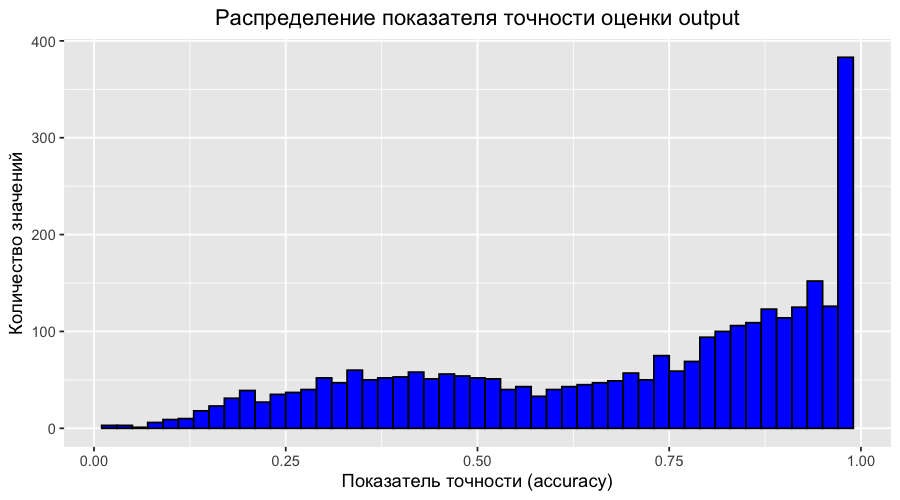

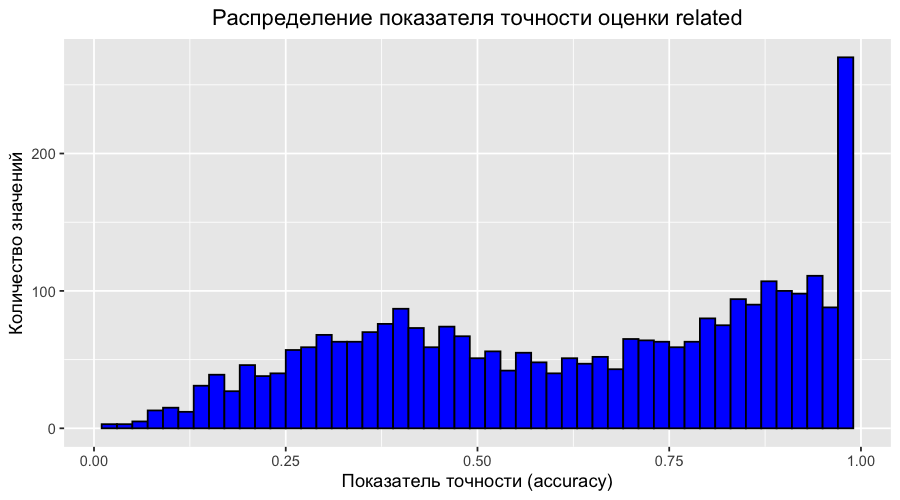

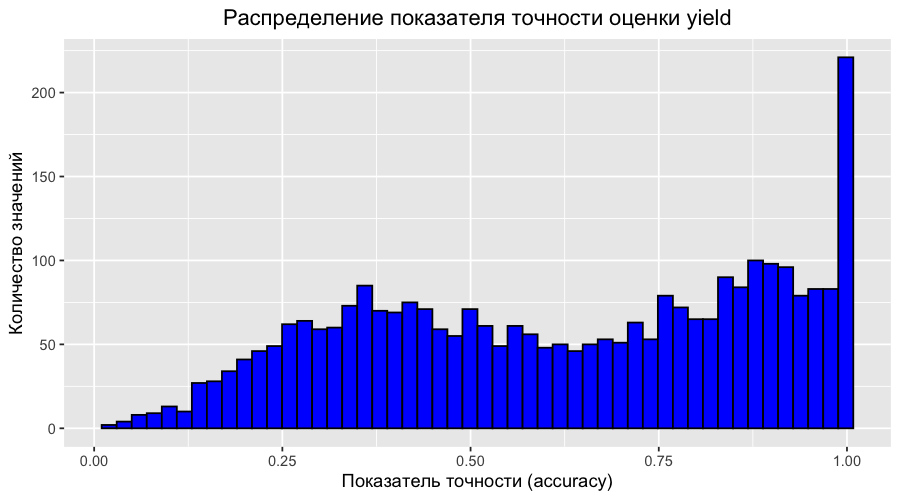

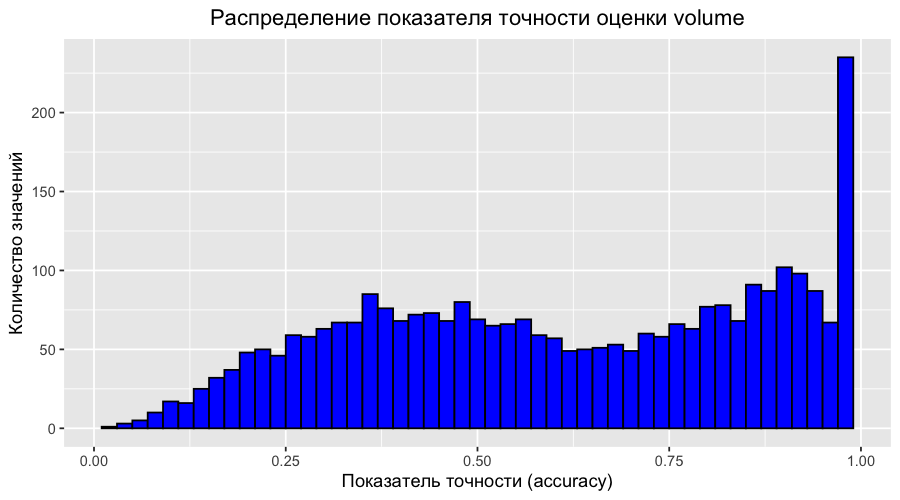

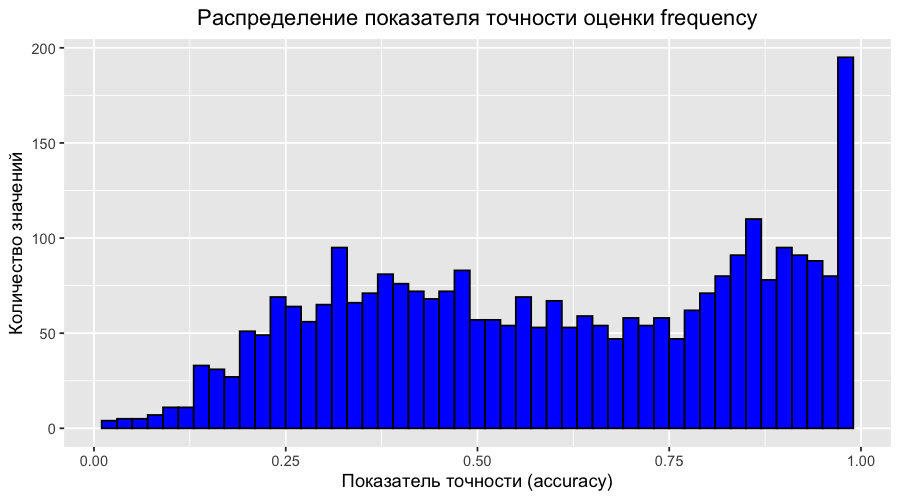

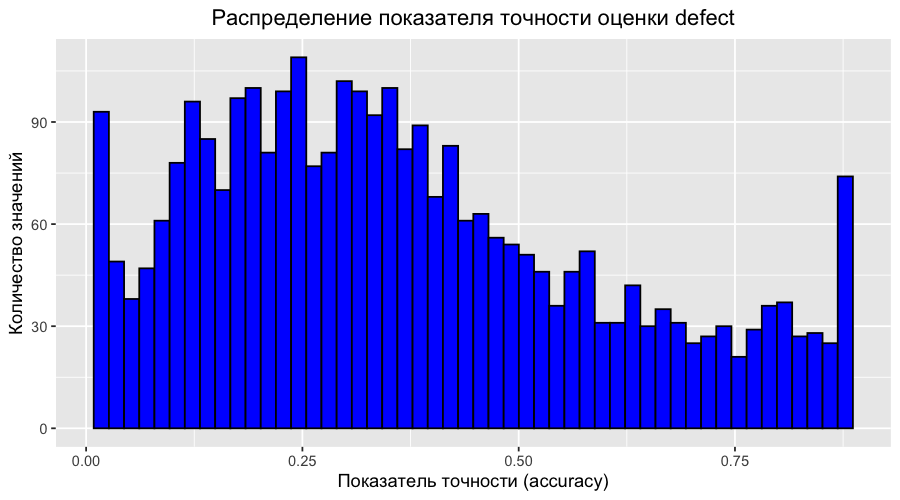

            output             related             yield            
data        data.frame,23      data.frame,23       data.frame,23    
layers      list,1             list,1              list,1           
scales      ScalesList,2       ScalesList,2        ScalesList,2     
guides      Guides,2           Guides,2            Guides,2         
mapping     ~.data[["output"]] ~.data[["related"]] ~.data[["yield"]]
theme       list,1             list,1              list,1           
coordinates CoordCartesian,5   CoordCartesian,5    CoordCartesian,5 
facet       FacetNull,2        FacetNull,2         FacetNull,2      
plot_env    ?                  ?                   ?                
layout      Layout,1           Layout,1            Layout,1         
labels      list,4             list,4              list,4           
            volume             frequency             defect            
data        data.frame,23      data.frame,23         data.frame,23     
layers      list,1          

In [7]:
sapply(metrics, function(x){print(histogram_distribution(dataset, x))})


На основании графика распределения мы наблюдаем в подавляющем большинстве точность > 0.8, однако также присутствуют изделия с точностью 0.5 и ниже. В расчёте оценки с использованием данных по браку **defect** наблюдается преобладание оценки 0.5 и ниже. Мы проанализируем полученные результаты более подробно.

### 1.2. Анализ точности оценок в зависимости от наличия фактических измерений
Любая прогнозная оценка зависит от наличия фактических измерений у изделия в большей или в меньшей степени. Здесь мы проверим эту зависимость.


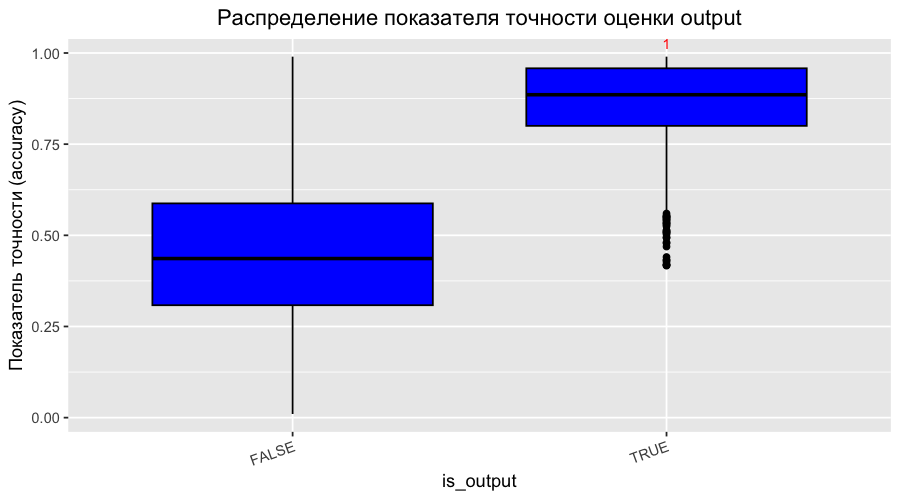

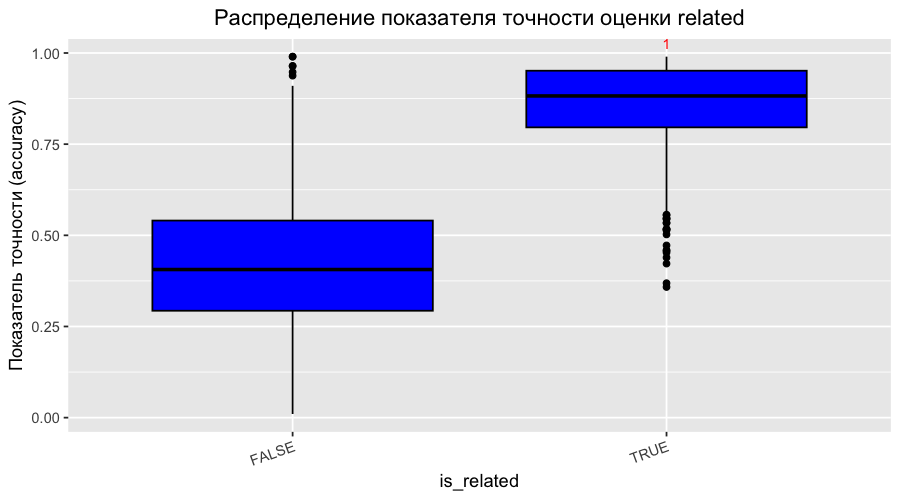

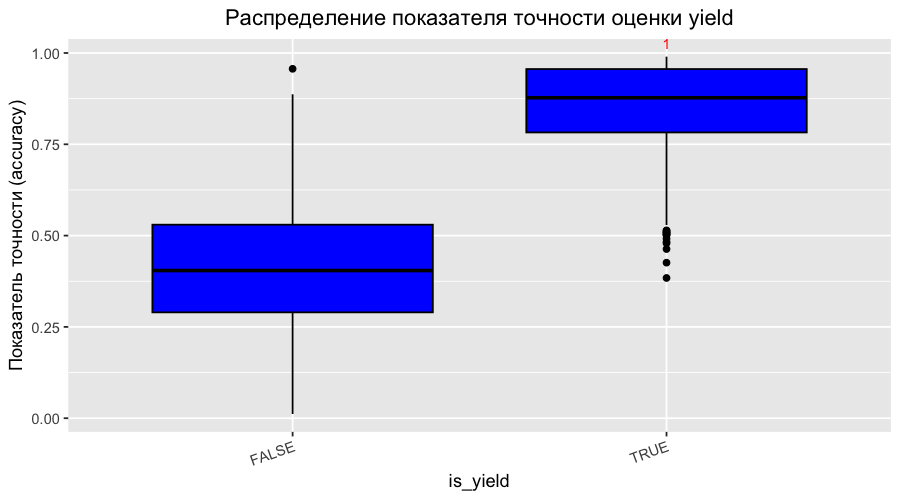

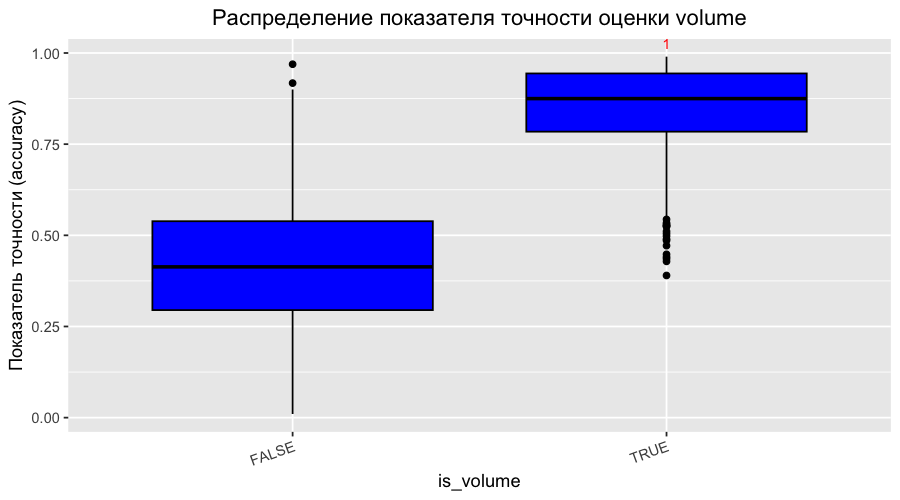

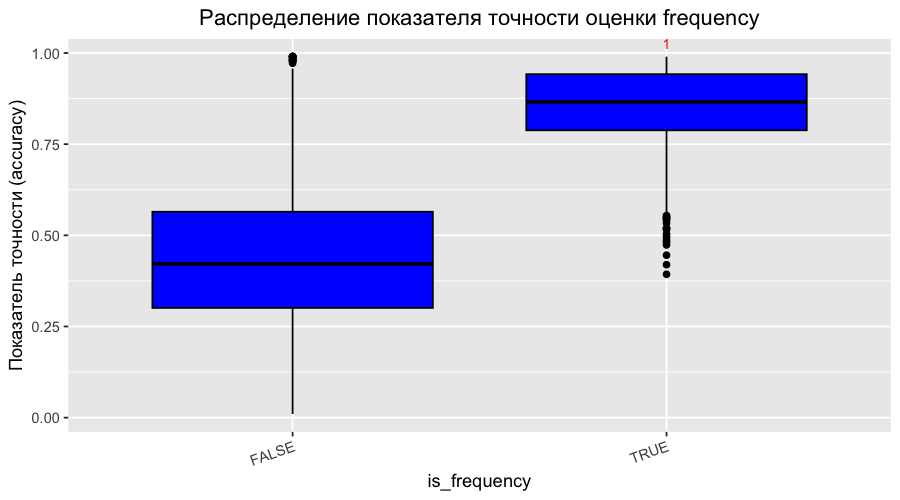

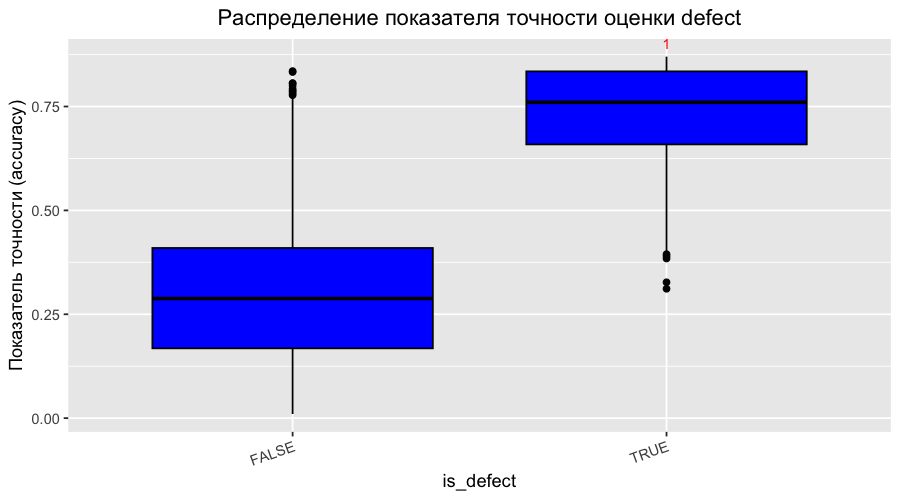

            output           related          yield            volume          
data        data.frame,23    data.frame,23    data.frame,23    data.frame,23   
layers      list,2           list,2           list,2           list,2          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     uneval,2         uneval,2         uneval,2         uneval,2        
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [8]:
sapply(metrics, function(x){print(boxplot_distribution(dataset, paste0('is_', x), x))})


После выполнения анализа показателя точности в зависимости от наличия фактических измерений самого изделия делается вывод, что *точность оценки прямо пропорционально зависит от наличия фактических измерений самого изделия*, и графики это наглядно демонстрируют. В своём подавляющем большинстве эта точность превышает 0.8. Те значения, которые не входят в этот диапазон, являются, скорее, опечатками.

Также мы провели односторонний статистический тест Манна-Уитни на определение зависимости прогнозной оценки от фактических измерений. H0: показатели точности оценки у изделий с фактическими измерениями не лучше, чем у изделий без них; H1: показатели точности оценки у изделий с фактическими измерениями лучше, чем у изделий без них 


In [9]:
knitr::kable(data.frame(
  pvalue = sapply(metrics, function(x) {wilcox.test(dataset_measured(dataset, x, TRUE), dataset_measured(dataset, x, FALSE), alternative='greater')$p.value}),
  statistic = sapply(metrics, function(x) {wilcox.test(dataset_measured(dataset, x, TRUE), dataset_measured(dataset, x, FALSE), alternative='greater')$statistic})
  ))


Using one column matrices in `filter()` was deprecated in dplyr 1.1.0.
ℹ Please use one dimensional logical vectors instead.




|          | pvalue| statistic|
|:---------|------:|---------:|
|output    |      0|   2050217|
|related   |      0|   2190866|
|yield     |      0|   2195854|
|volume    |      0|   2163219|
|frequency |      0|   2042882|
|defect    |      0|   1214212|


На основании результатов статистического теста мы отвергаем нулевую гипотезу о том, что данные показатели точности оценки у изделий с фактическими измерениями не лучше, чем у изделий без них. Мы видим, что показатели точности оценок у изделий с измерениями намного лучше, чем у изделий без них, о чём говорит очень высокий показатель статистики


### 1.3. Анализ точности оценок в зависимости от типа


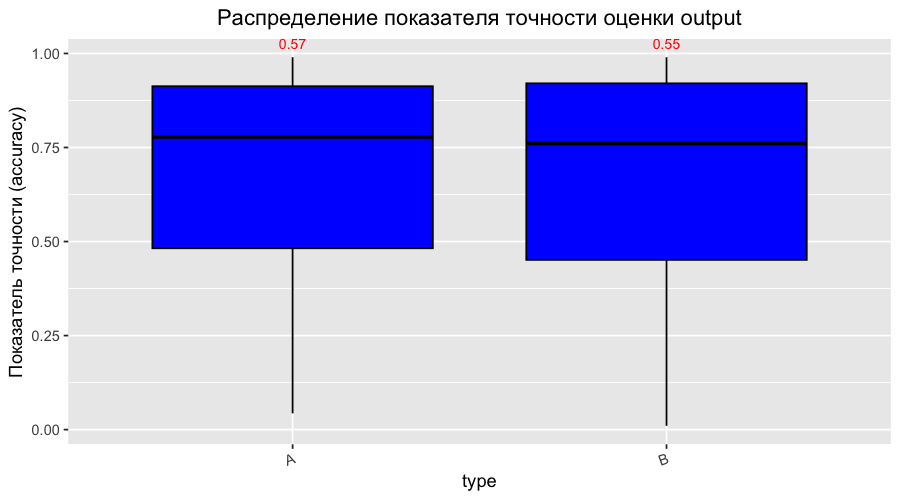

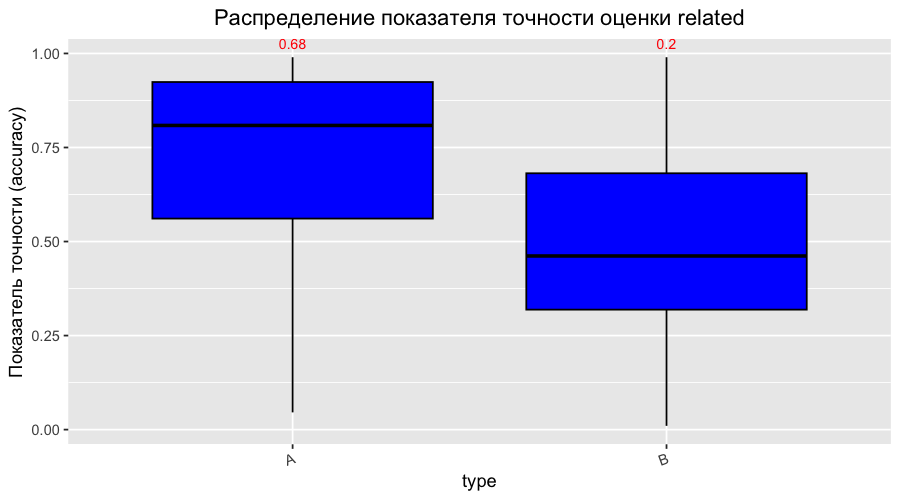

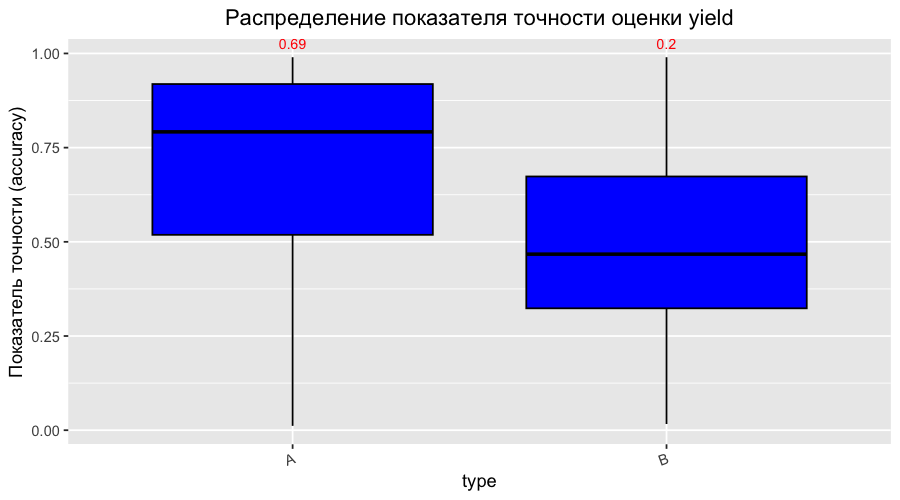

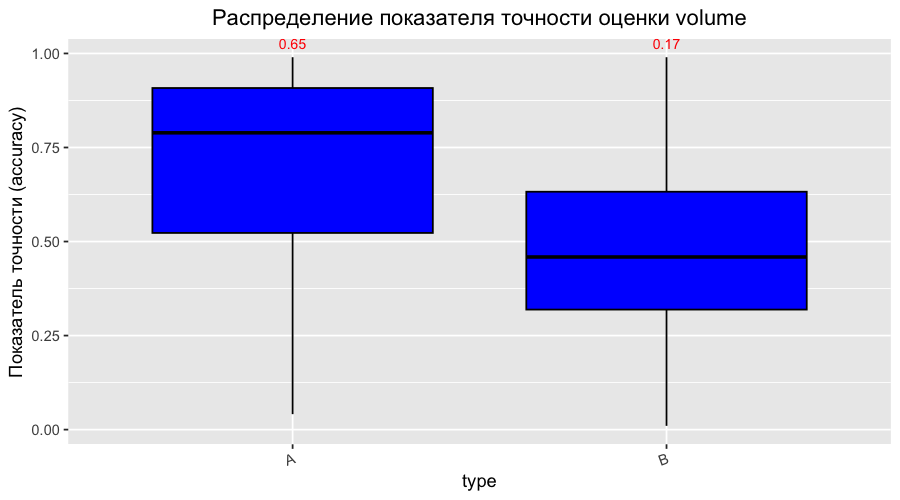

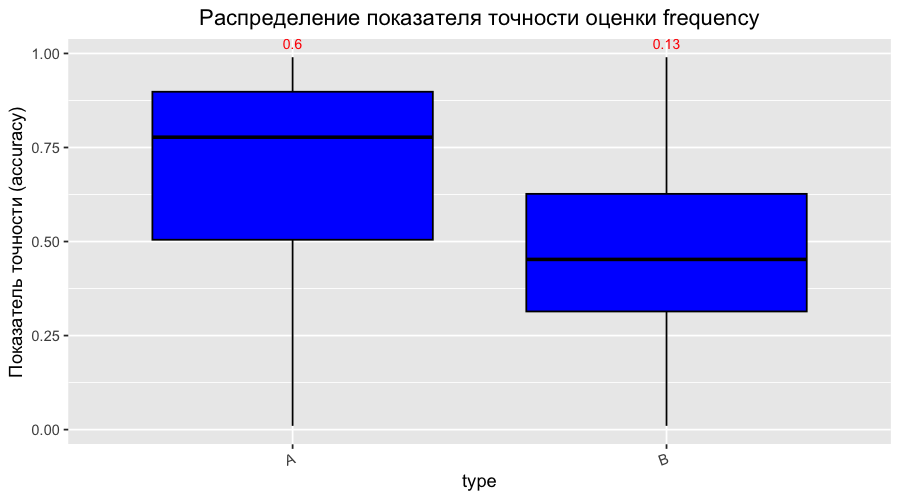

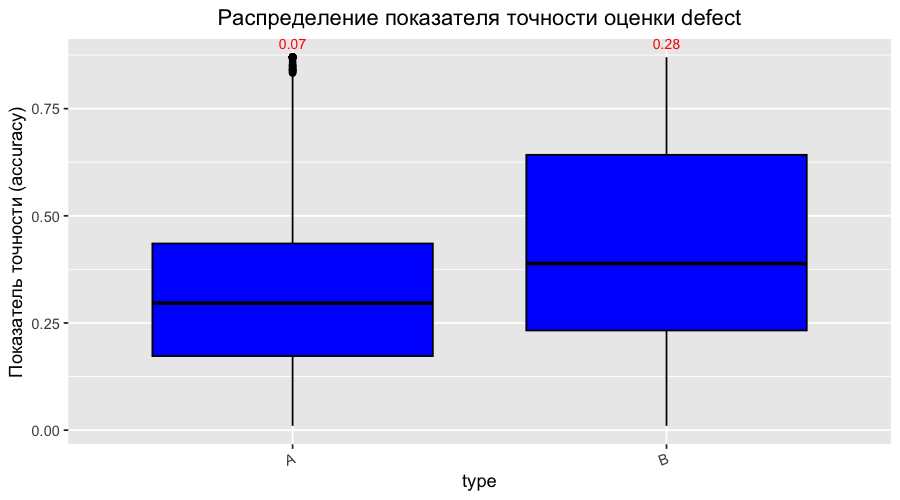

            output           related          yield            volume          
data        data.frame,23    data.frame,23    data.frame,23    data.frame,23   
layers      list,2           list,2           list,2           list,2          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     uneval,2         uneval,2         uneval,2         uneval,2        
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [10]:
sapply(metrics, function(x) {print(boxplot_distribution(dataset, 'type', x))})


При анализе зависимости типа изделия от показателя точности прогнозной оценки мы наблюдаем схожую ситуацию. При расчёте точности оценки по производительности (*output*) мы видим примерно равные значения Q2 и примерно равное распределение. Это объясняется тем, что доля фактических измерений у обоих типов достаточно высокая, при этом у типа B доля выше и, соответственно, Q2 оценки тоже выше. Однако при расчёте других прогнозных оценок, где в измерениях присутствует только один тип, у оценок противоположного типа средний показатель точности сильно ниже. Особо стоит отметить оценки по частоте выпуска и по браку. В частоте выпуска у нас измерения по типу A, и даже по типу A доля измерений всего 0.63, и мы видим большой разброс оценок. По браку у нас измерения, преимущественно, по типу B, и там у нас крайне низкая доля фактических измерений, соответственно, мы видим тоже большой разброс показателя точности. Следовательно, вывод такой же, как и в предыдущей главе - показатель точности напрямую зависит от доли фактических измерений в оценках.

### 1.4. Анализ точности оценок в зависимости от сертификации


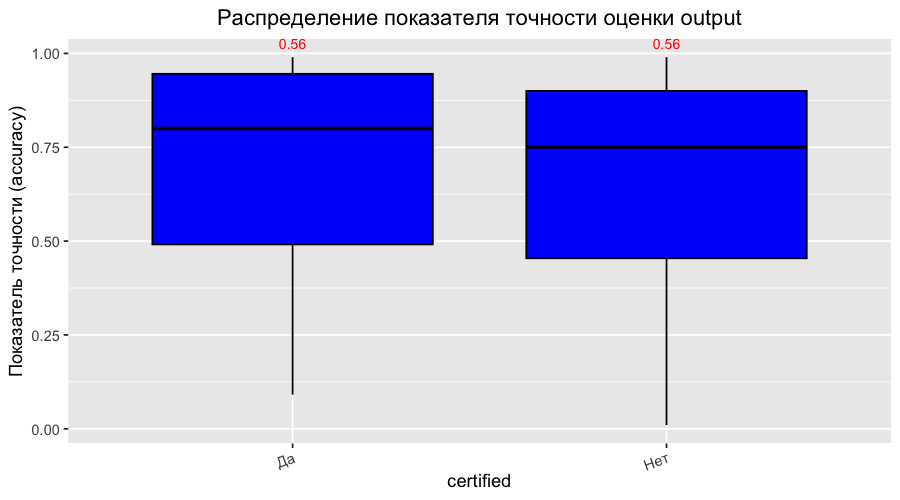

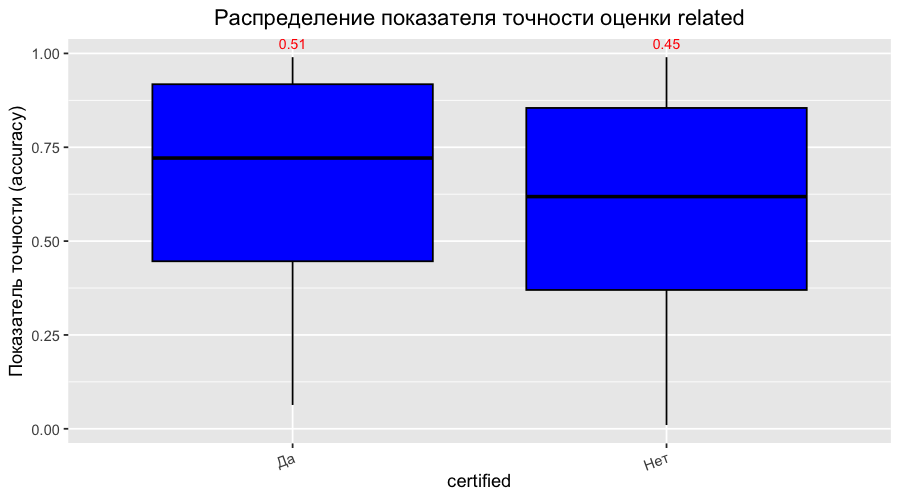

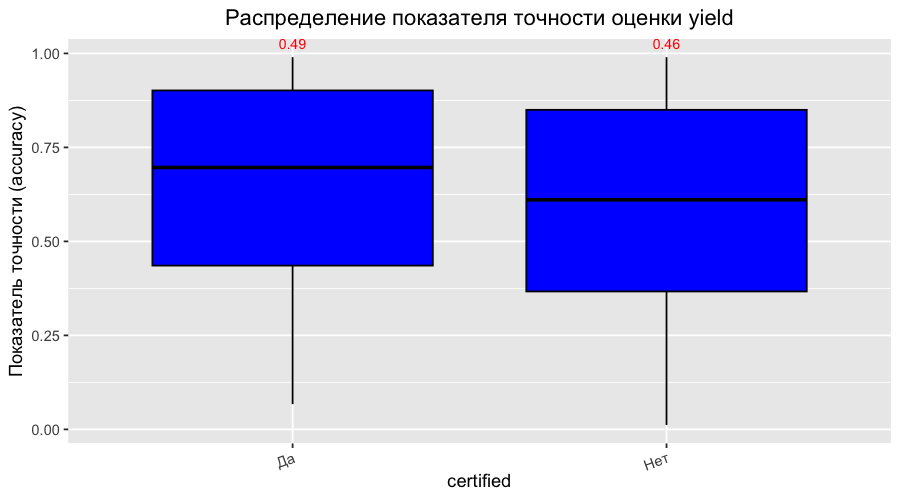

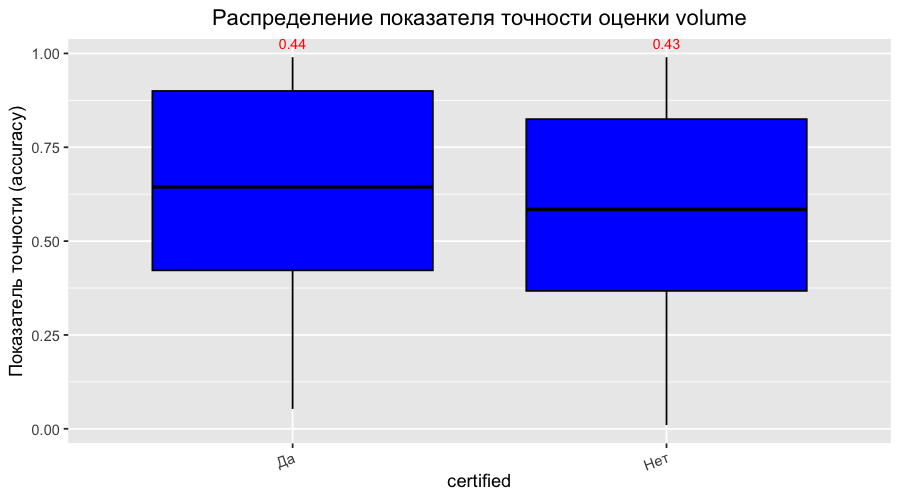

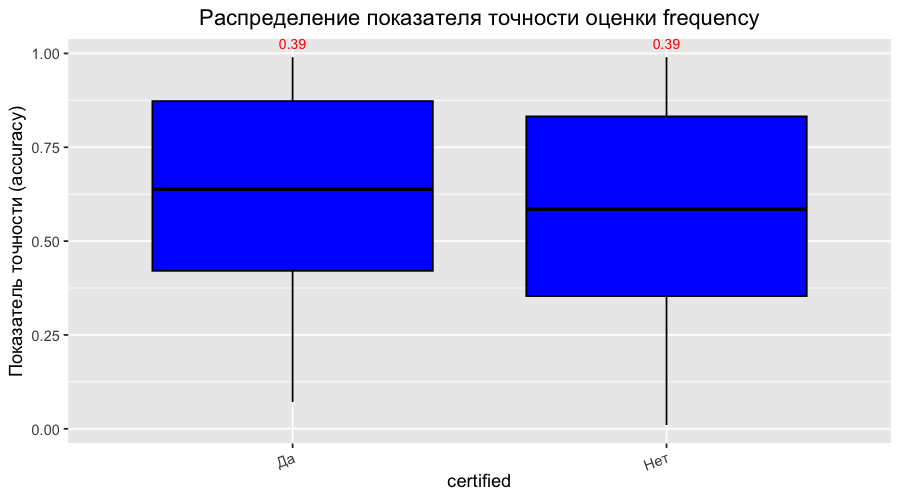

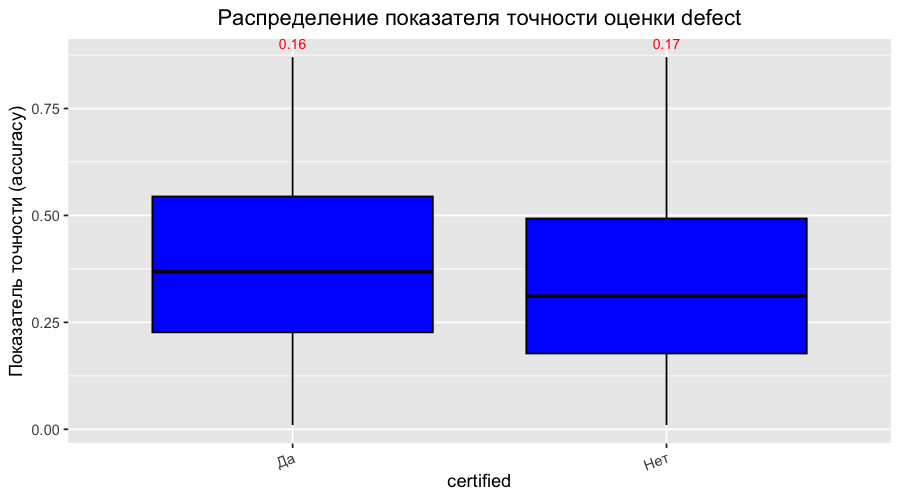

            output           related          yield            volume          
data        data.frame,23    data.frame,23    data.frame,23    data.frame,23   
layers      list,2           list,2           list,2           list,2          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     uneval,2         uneval,2         uneval,2         uneval,2        
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [11]:
sapply(metrics, function(x) {print(boxplot_distribution(dataset, 'certified', x))})


То же самое можно сказать и при анализе зависимости точности оценки от статуса сертификации изделия. Точность опять же, в первую очередь, напрямую зависит от наличия фактических измерений. Статус сертификации здесь уже на втором месте. Следовательно, здесь стоит рассмотреть возможность получения оценки только с использованием лабораторных данных изделия с помощью отдельной лабораторной модели. 

### 1.5. Анализ точности оценок в зависимости от серии


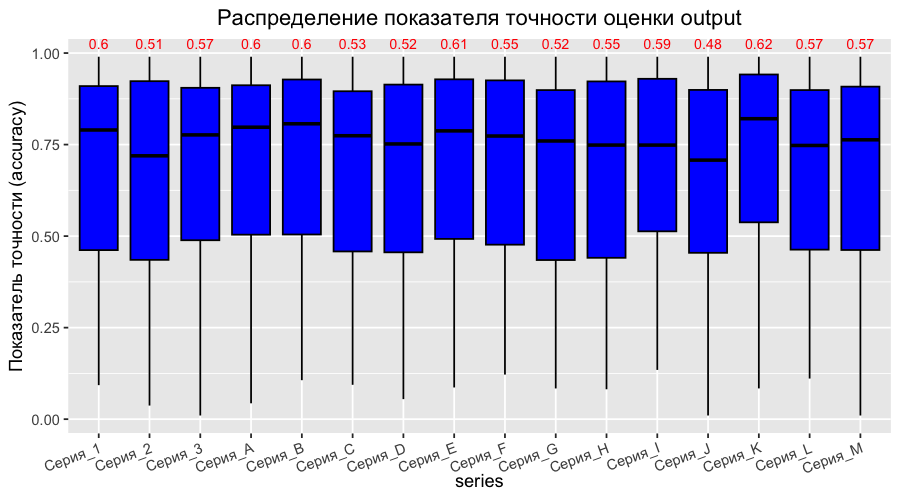

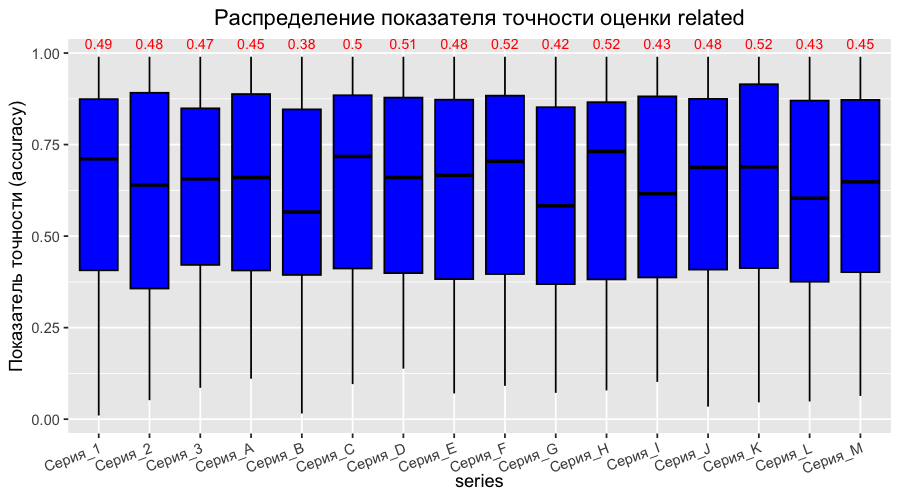

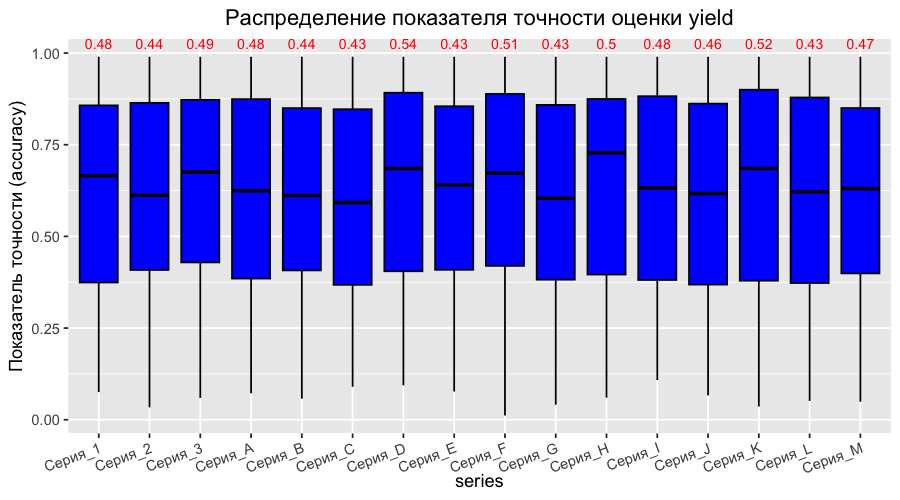

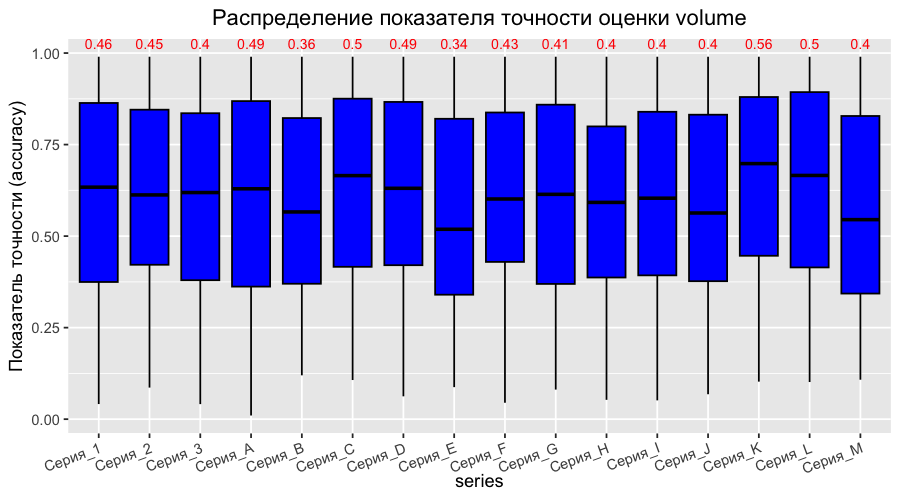

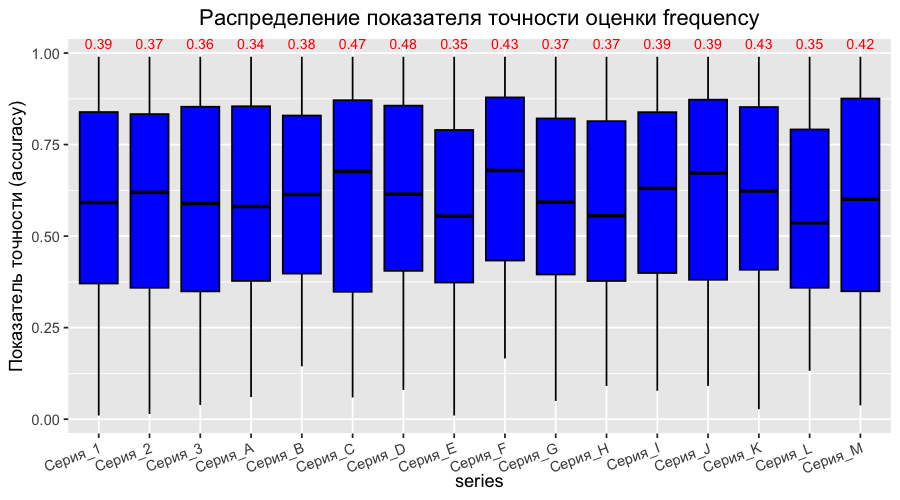

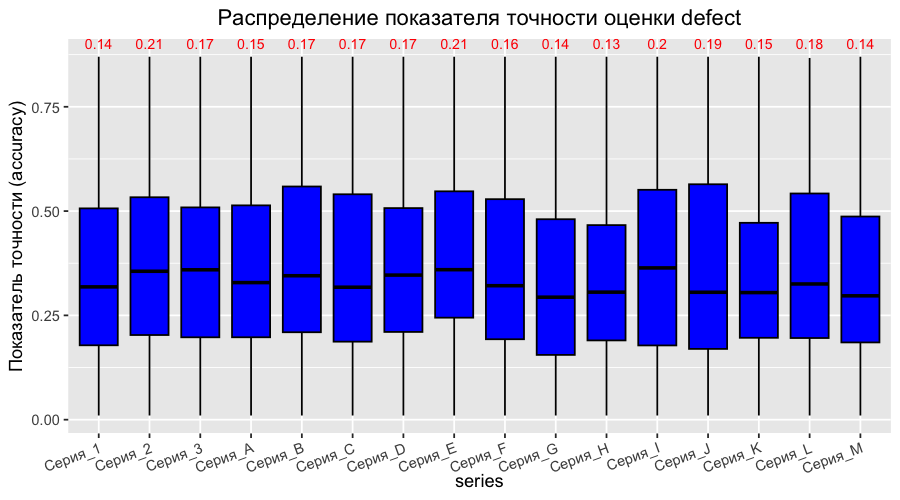

            output           related          yield            volume          
data        data.frame,23    data.frame,23    data.frame,23    data.frame,23   
layers      list,2           list,2           list,2           list,2          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     uneval,2         uneval,2         uneval,2         uneval,2        
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [12]:
sapply(metrics, function(x) {print(boxplot_distribution(dataset, 'series', x))})


Точно такой же вывод можно сделать при зависимости показателя точности от серии изделия. Если определённое изделие определённой серии есть в фактических измерениях, то точность прогнозной оценки такого изделия будет сильно выше, чем у изделия, которого нет в фактических измерениях. Чтобы получить высокую точность оценки изделия, доля фактических измерений должна быть не менее 0.5, о чём наглядно говорят графики.

Регрессионный анализ позволяет увидеть, насколько меняется средний показатель относительно интерсепта - значения определённой группы. Верхний красный ряд цифр обозначает среднее значение показателя интерсепта, в случае, если среднее значение - интерсепт. В остальном случае это показатели, насколько изменилось среднее значение как в положительную, так и в отрицательную сторону. Второй светло-красный ряд - это среднее значение показателя точности в зависимости от группы.


Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(var_1)

  # Now:
  data %>% select(all_of(var_1))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.


Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(var_2)

  # Now:
  data %>% select(all_of(var_2))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.


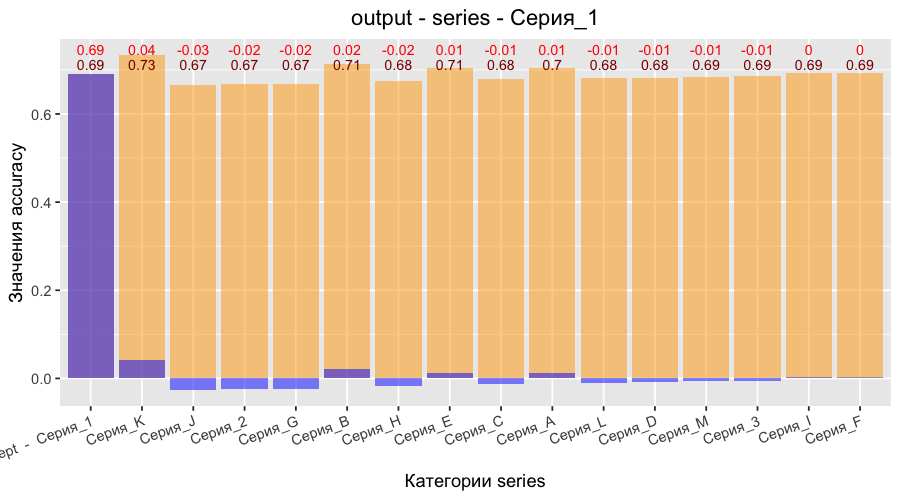

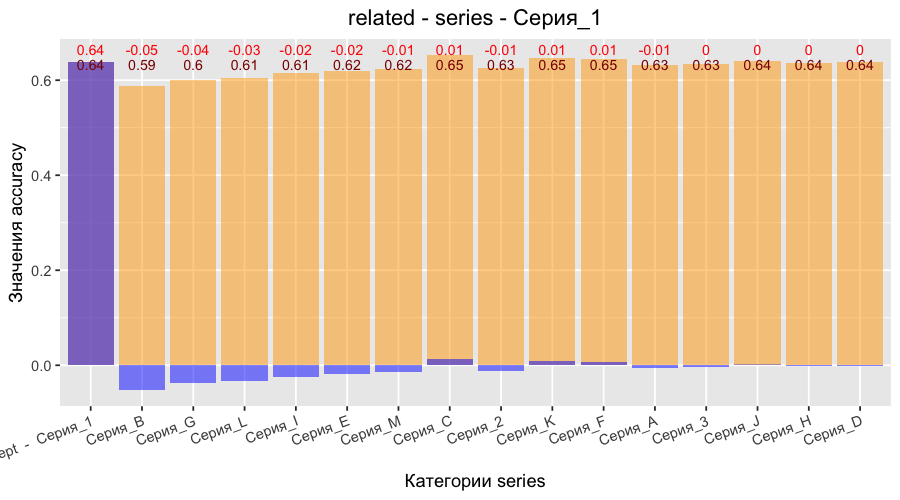

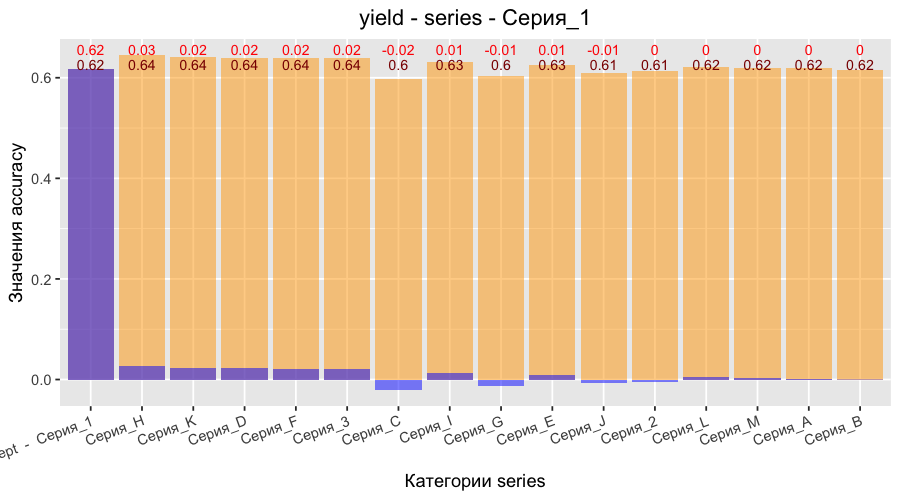

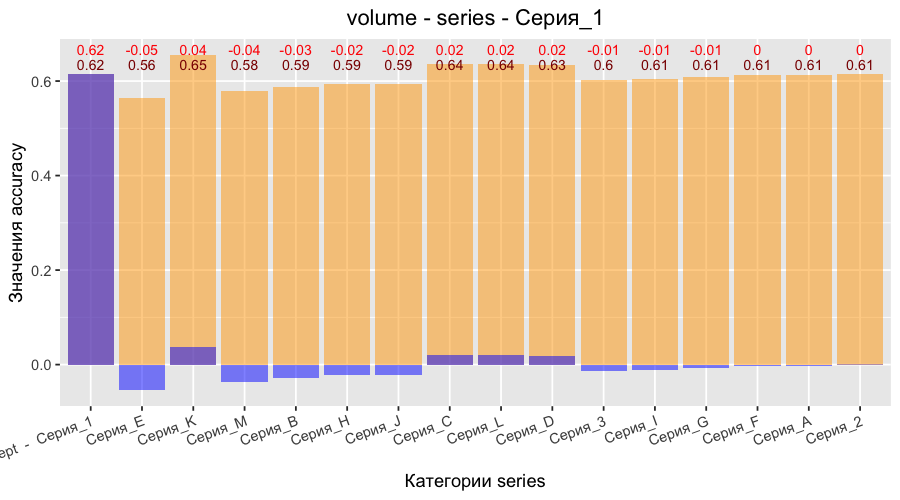

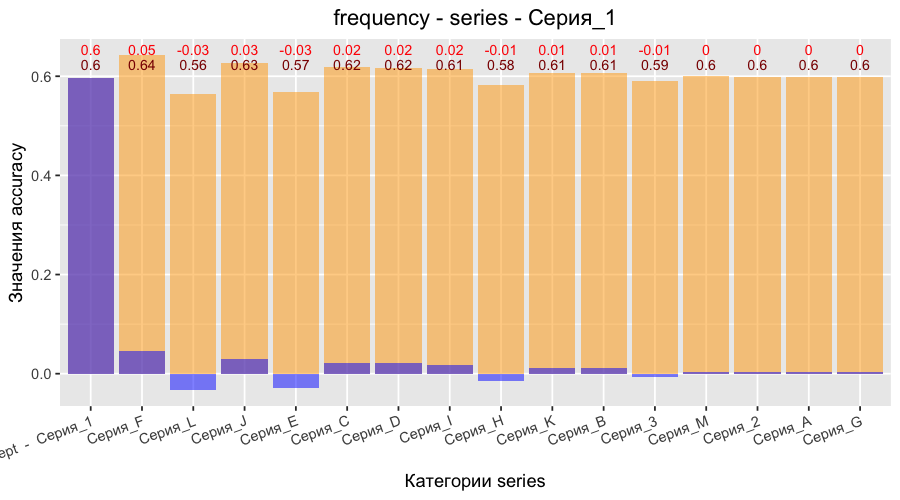

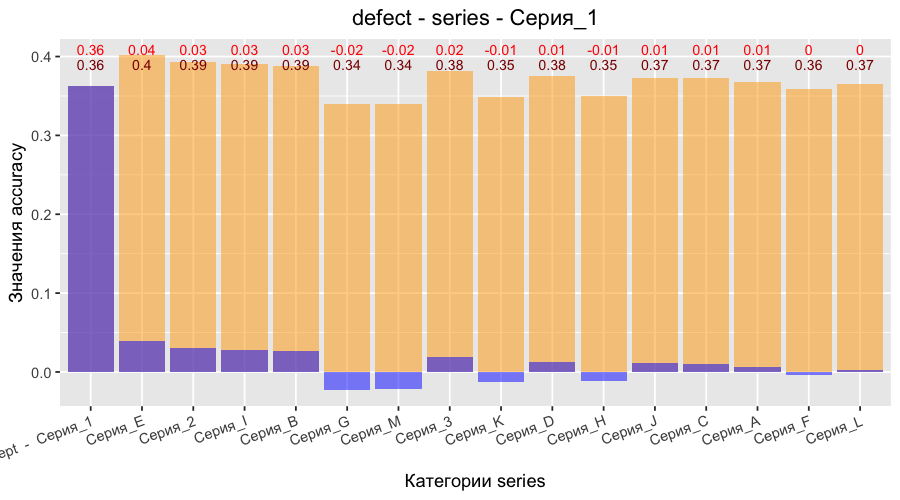

            output           related          yield            volume          
data        data.frame,4     data.frame,4     data.frame,4     data.frame,4    
layers      list,4           list,4           list,4           list,4          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     ~features        ~features        ~features        ~features       
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [13]:
sapply(metrics, function(x) {print(linear_model_cat(dataset, x, 'series', 'Серия_1'))})


При проведении регрессионного анализа точности оценок в зависимости от серии изделия за основу мы взяли Серию_1. Средний показатель у этой серии составляет 0.85. Наилучшие показатели получились у следующих серий: Серия_A, Серия_B, Серия_C, Серия_D, Серия_E, Серия_F, Серия_G. Наихудшие показатели получились у серий Серия_H, Серия_I, Серия_J, Серия_K, Серия_L, Серия_M. 

### 1.6. Анализ точности оценок в зависимости от года выпуска


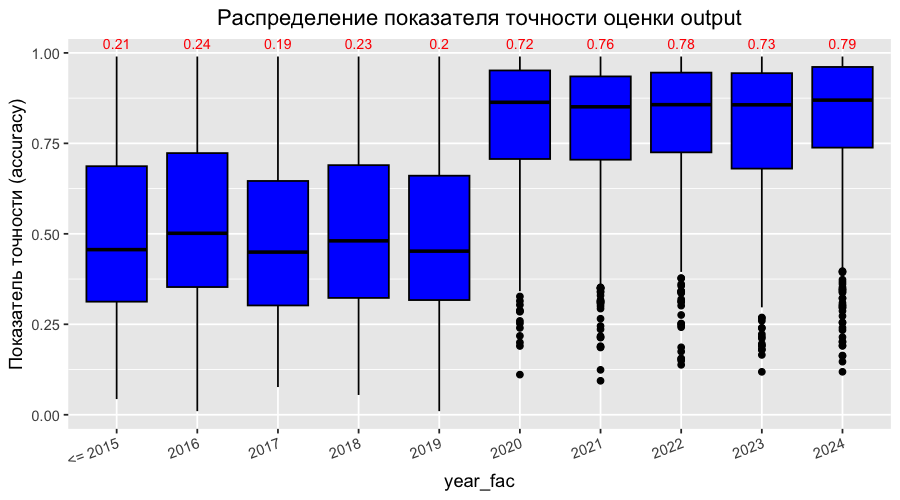

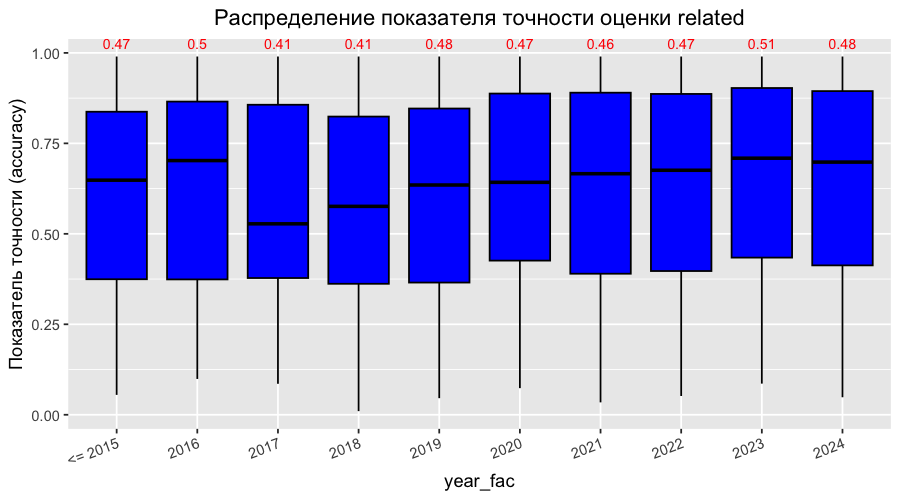

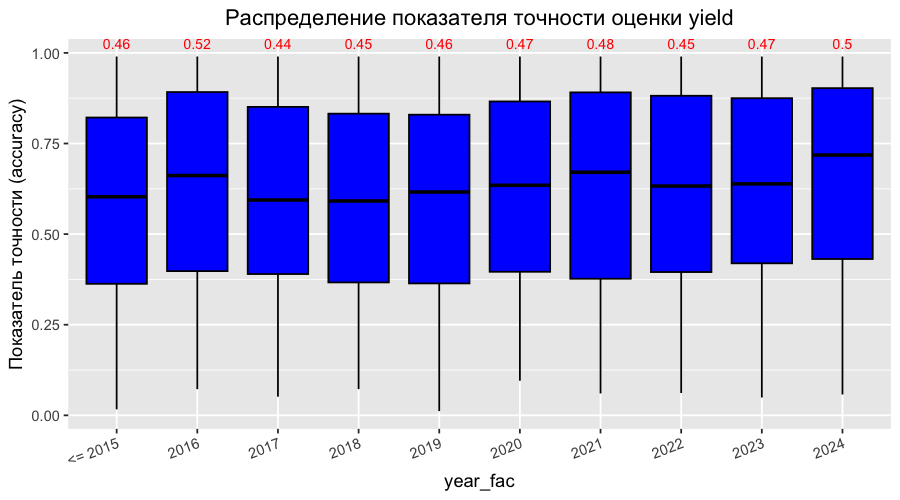

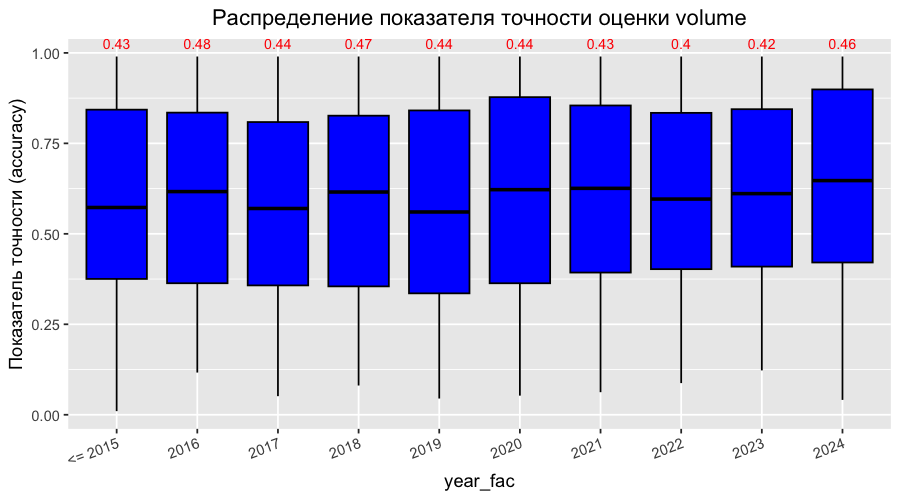

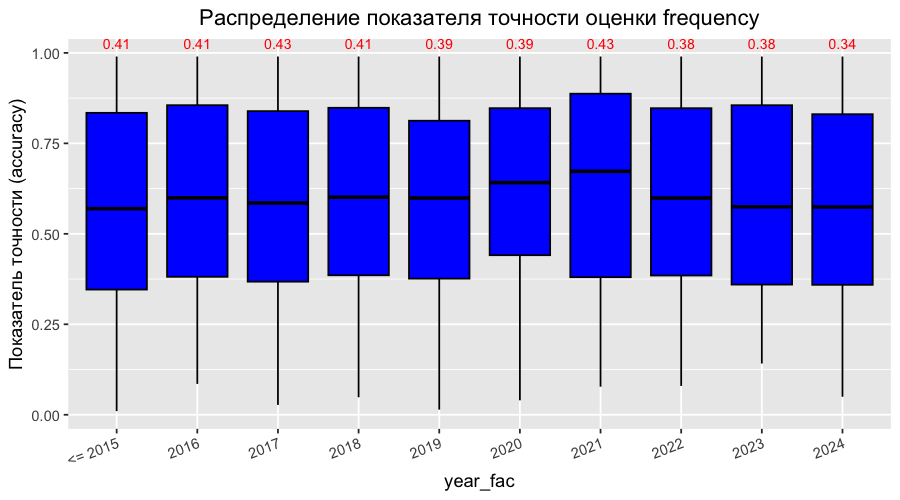

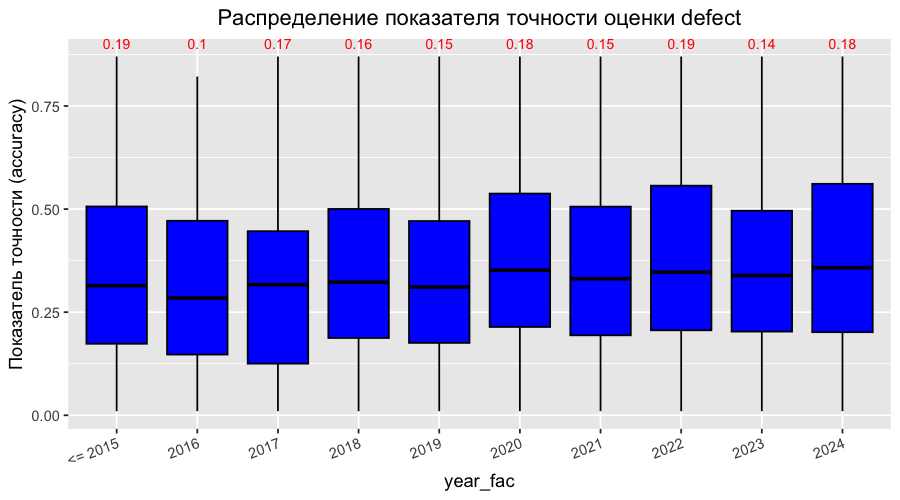

            output           related          yield            volume          
data        data.frame,23    data.frame,23    data.frame,23    data.frame,23   
layers      list,2           list,2           list,2           list,2          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     uneval,2         uneval,2         uneval,2         uneval,2        
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [14]:
sapply(metrics, function(x) {print(boxplot_distribution(dataset, 'year_fac', x))})


После выполнения анализа показателя точности в зависимости от года выпуска изделия мы наблюдаем схожую картину:

- При расчёте показателя в данных по производительности (**output**) мы наблюдаем высокие показатели точности у изделий, выпущенных после 2020 года и сильно низкие показатели у изделий, выпущенных до 2020 года. Это обусловлено отсутствием фактических измерений у таких изделий. Доля фактических измерений у изделий, выпущенных после 2020 года, крайне высока!

- При расчёте показателя по сопутствующему выпуску, выходу годного, объёму партии, частоте выпуска и браку мы наблюдаем достаточно низкие показатели точности в последние годы или их отсутствие. Это также обусловлено отсутствием данных за этот период. В остальных данных наблюдается точно такая же картина - наличие фактических измерений напрямую влияет на точность оценки!


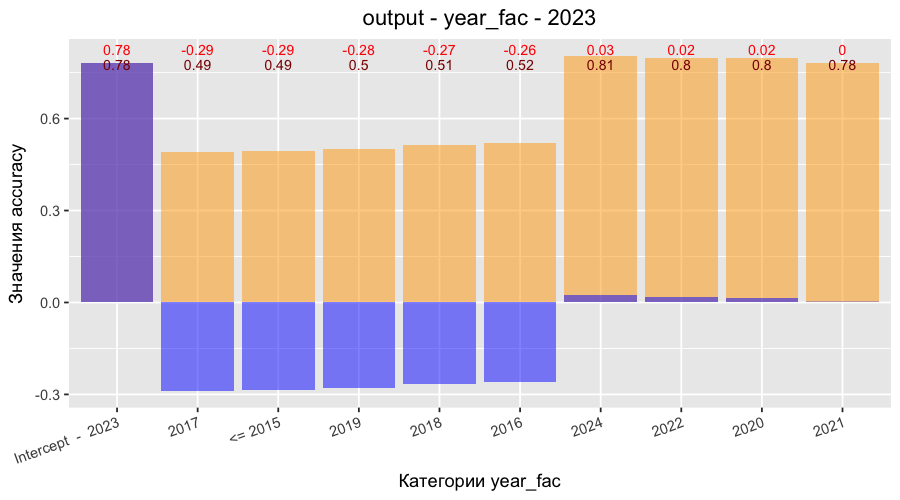

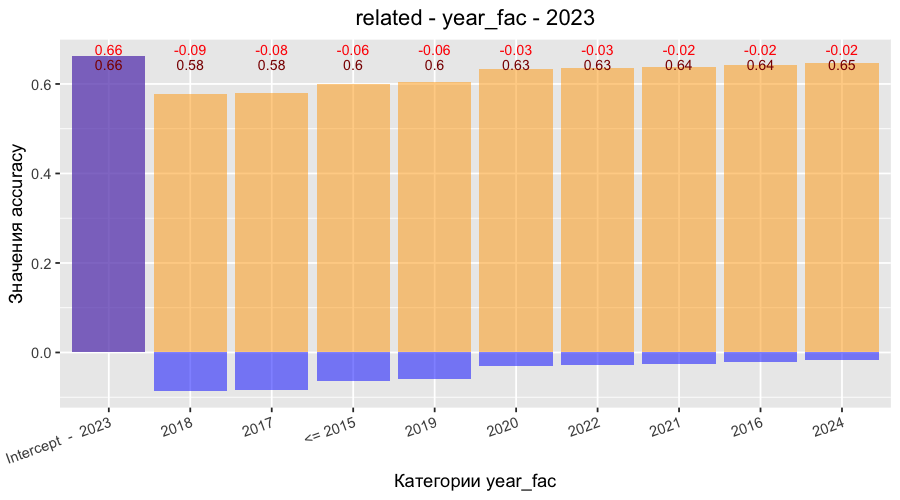

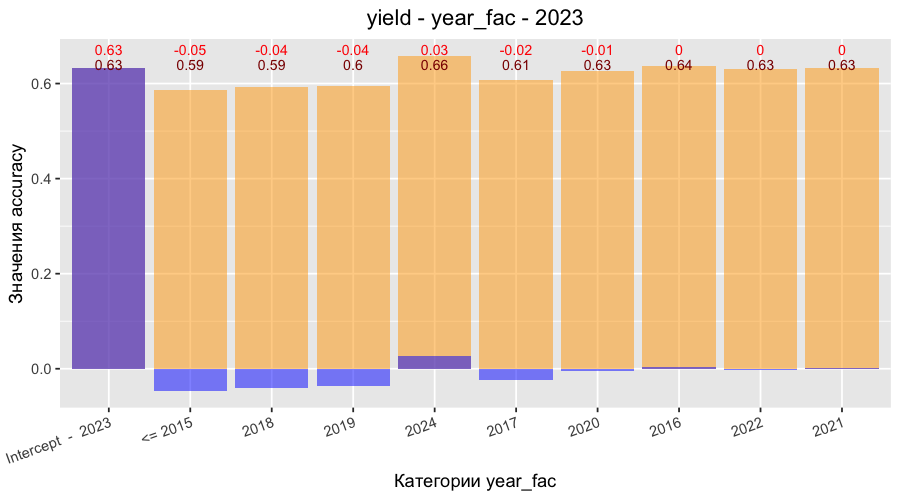

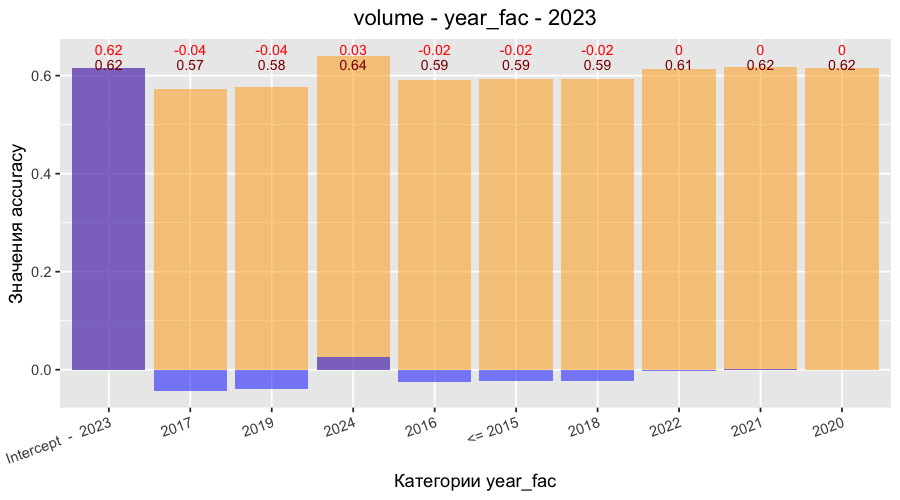

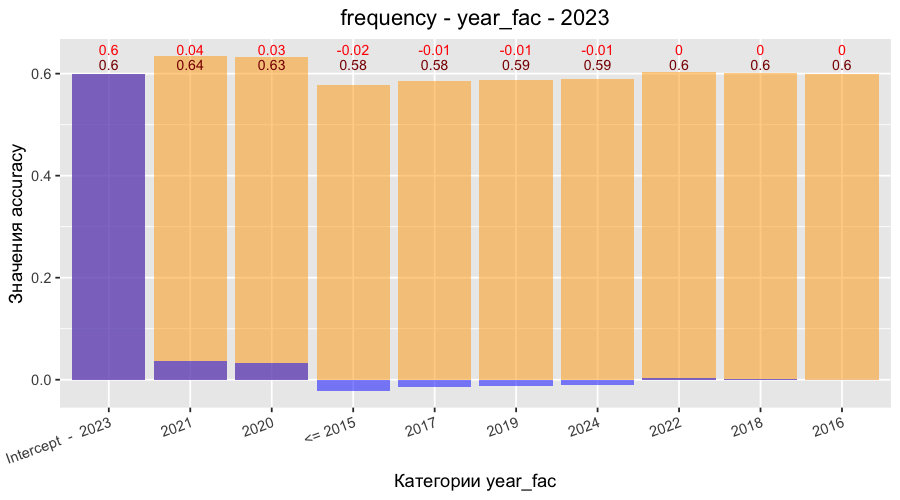

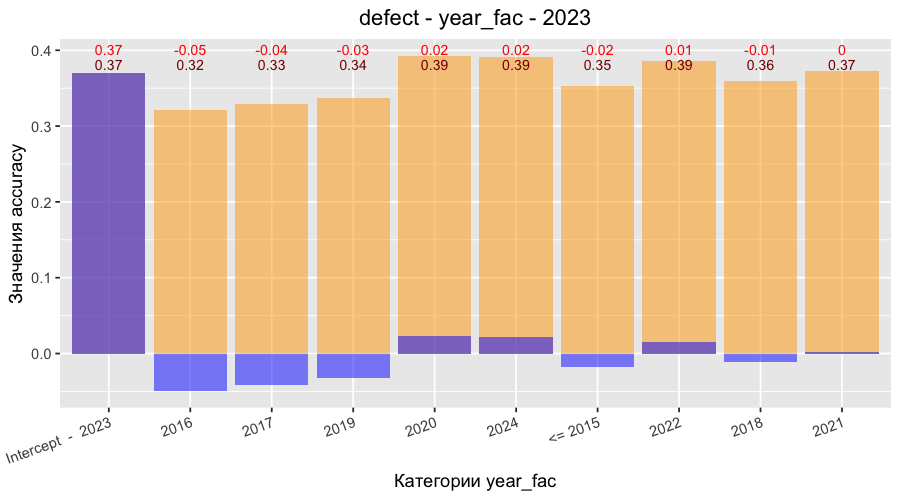

            output           related          yield            volume          
data        data.frame,4     data.frame,4     data.frame,4     data.frame,4    
layers      list,4           list,4           list,4           list,4          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     ~features        ~features        ~features        ~features       
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [15]:
sapply(metrics, function(x) {print(linear_model_cat(dataset, x, 'year_fac', '2023'))})


А при проведении регрессионного анализа точности оценок в зависимости от года за основу мы взяли год выпуска 2023. Средний показатель у этого года составляет 0.82. Больше только у изделий 2022 и 2024 годов выпуска. Чуть-чуть меньше у изделий 2020 и 2021 годов выпуска. А у изделий с датой выпуска 2018 и меньше показатель точности не дотягивает даже до уровня 0.4. 

# 2. Анализ точности полученных оценок при отсутствии фактических измерений

Точность полученных оценок изделий, у которых отсутствуют фактические измерения, вызывает большой интерес. Здесь показывают своё влияние второстепенные факторы, которые используются при оценке в основной модели - связанные позиции и лабораторные данные. В этой части мы проведём такой анализ и оценим такое влияние.


In [16]:
dataset_unmeasured <- function(data, pipe) {
  result <- data %>% filter(data[paste0('is_', pipe)] == FALSE)
  return(result)
}

dataset_unmeasured_linked <- function(data, pipe, measured) {
  result <- data %>%
    filter(data[paste0('is_', pipe)] == FALSE) %>%
    mutate(has_linked = case_when(parent_a_id %in% measured | parent_b_id %in% measured ~ 'Да', TRUE ~ 'Нет'))
  return(result)
}

dataset_unmeasured_cat <- function(data, pipe, category, value) {
  result <- data %>% 
    filter(data[paste0('is_', pipe)] == FALSE & data[category] == value)
  return(result[[pipe]])
}


### 2.1. Общий расчёт точности полученных оценок изделий без фактических измерений


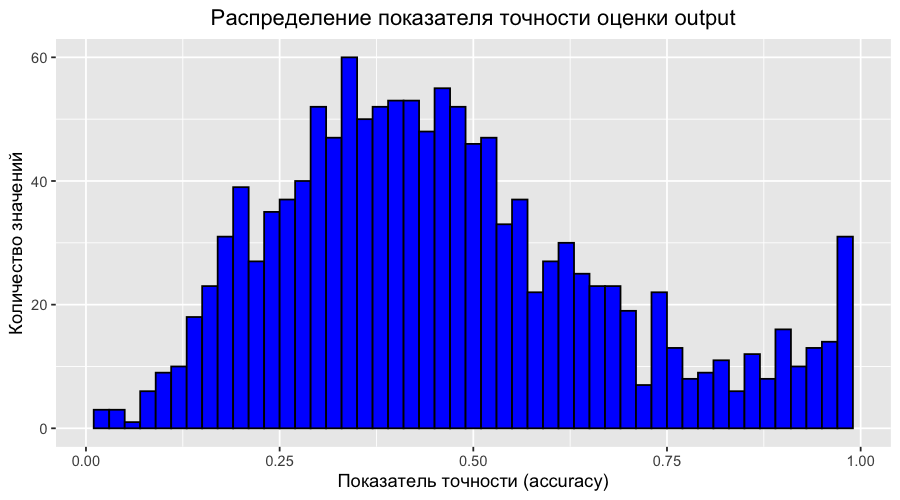

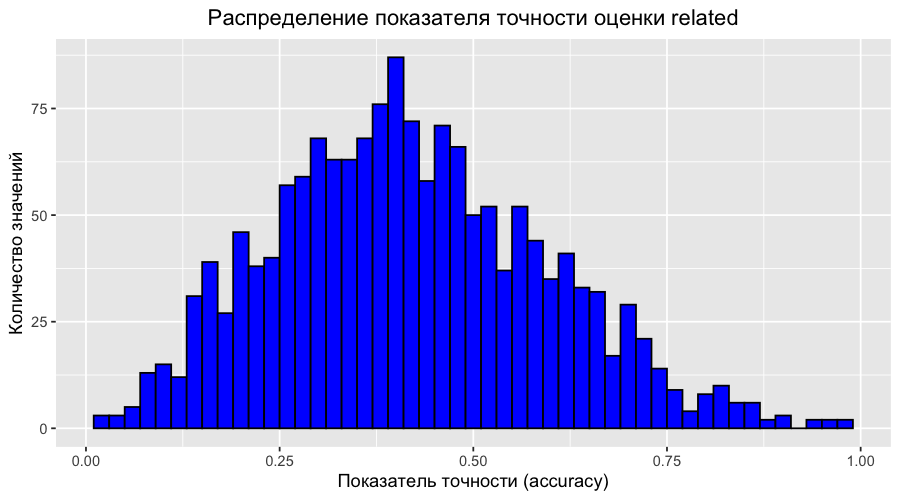

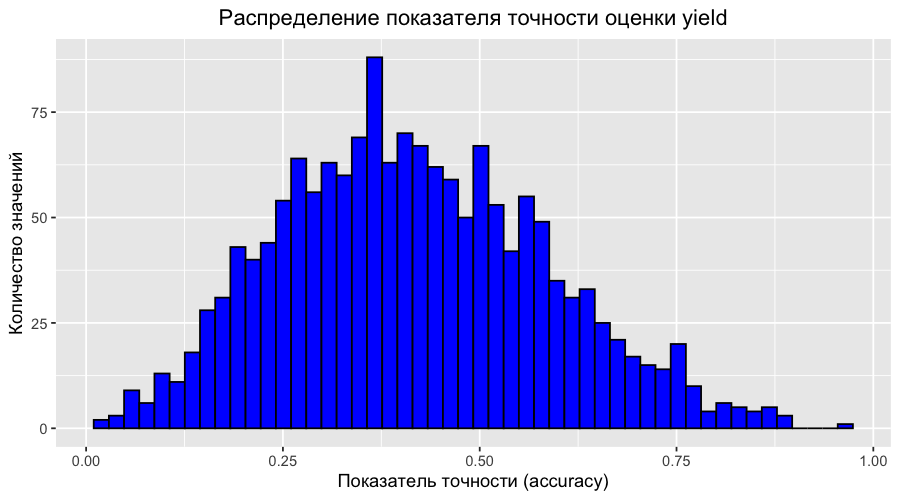

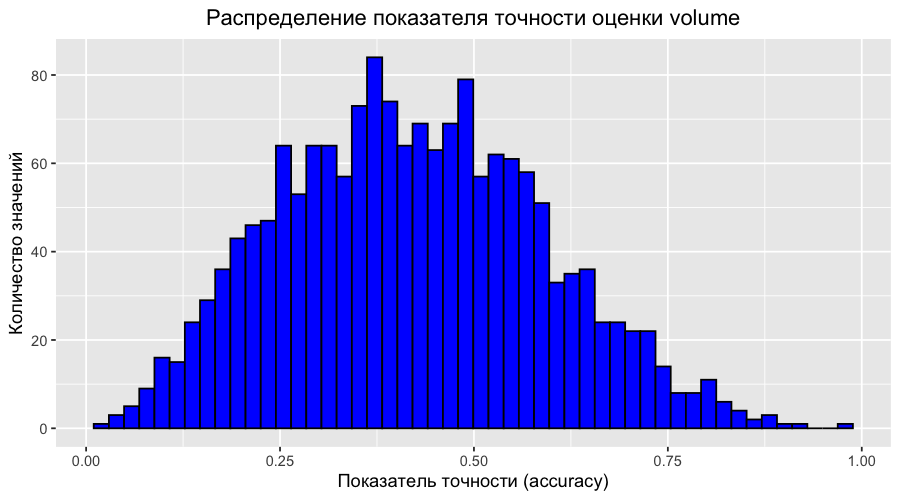

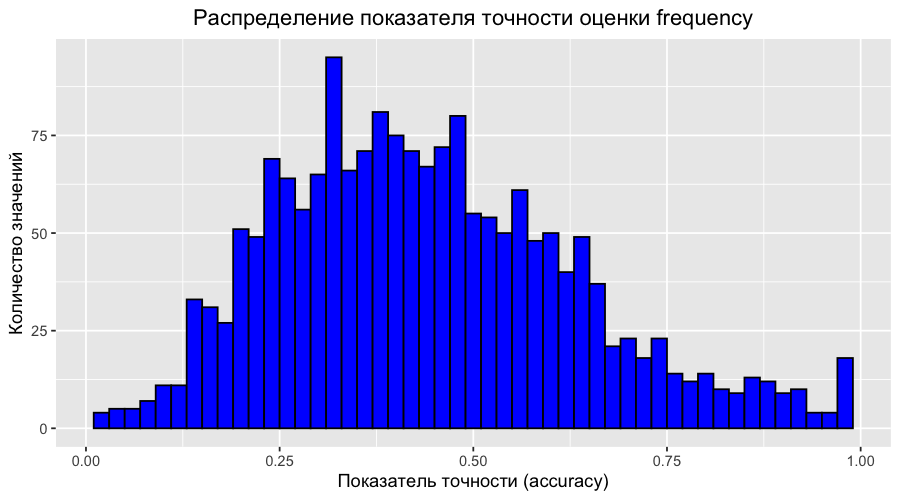

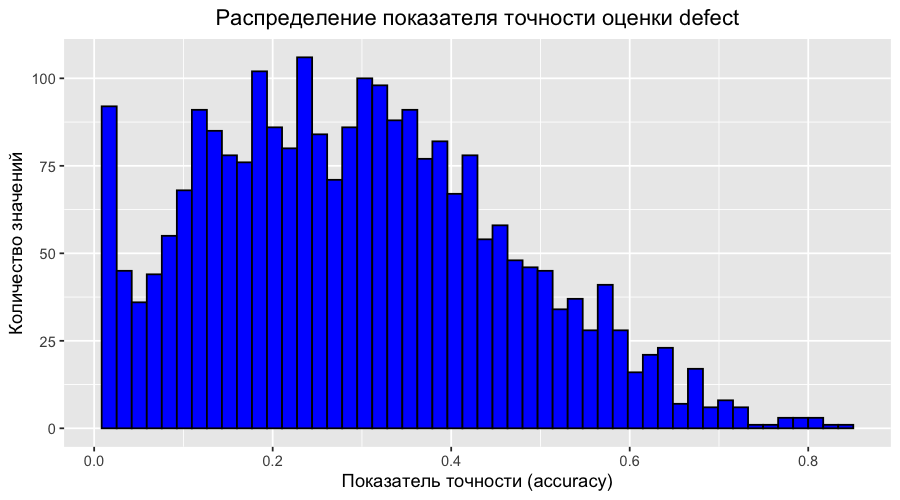

            output             related             yield            
data        data.frame,23      data.frame,23       data.frame,23    
layers      list,1             list,1              list,1           
scales      ScalesList,2       ScalesList,2        ScalesList,2     
guides      Guides,2           Guides,2            Guides,2         
mapping     ~.data[["output"]] ~.data[["related"]] ~.data[["yield"]]
theme       list,1             list,1              list,1           
coordinates CoordCartesian,5   CoordCartesian,5    CoordCartesian,5 
facet       FacetNull,2        FacetNull,2         FacetNull,2      
plot_env    ?                  ?                   ?                
layout      Layout,1           Layout,1            Layout,1         
labels      list,4             list,4              list,4           
            volume             frequency             defect            
data        data.frame,23      data.frame,23         data.frame,23     
layers      list,1          

In [17]:
sapply(metrics, function(x){data = dataset_unmeasured(dataset, x); print(histogram_distribution(data, x))})


При общем анализе мы видим, что у изделий с отсутствующими лабораторными данными точность оценки невысокая. Очень мало изделий с оценкой 0.8 и выше. С одной стороны - это ожидаемо, ведь изделие без фактических измерений оценить сложнее, с другой стороны это говорит о низком влиянии связанных позиций и лабораторных данных на полученную оценку.

### 2.2. Анализ точности оценок изделий без фактических измерений в зависимости от статуса наличия измерений у связанных позиций

При таком анализе изделий мы разделили все изделия на категории: изделия, у которых связанные позиции есть в фактических измерениях, и изделия, у которых связанных позиций нет в фактических измерениях.


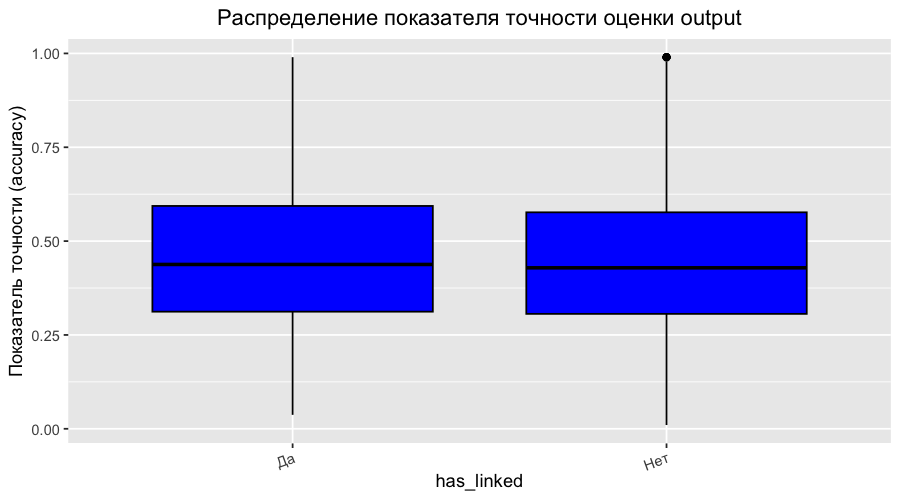

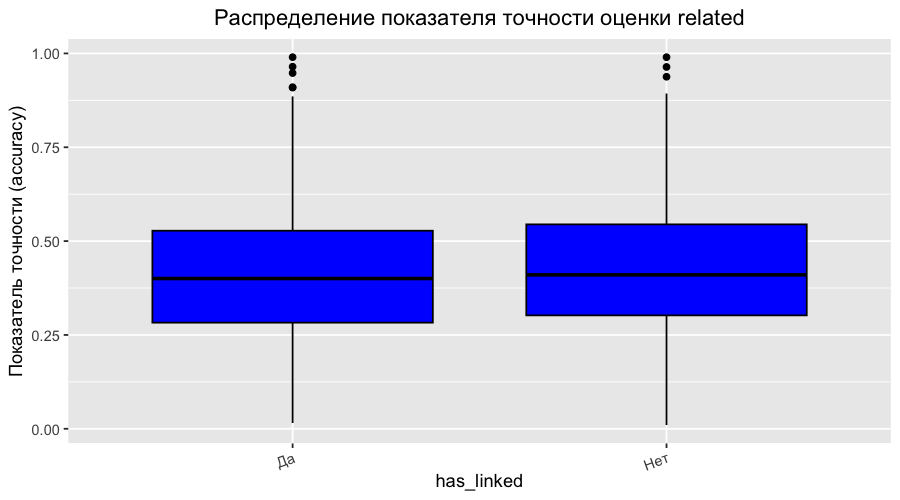

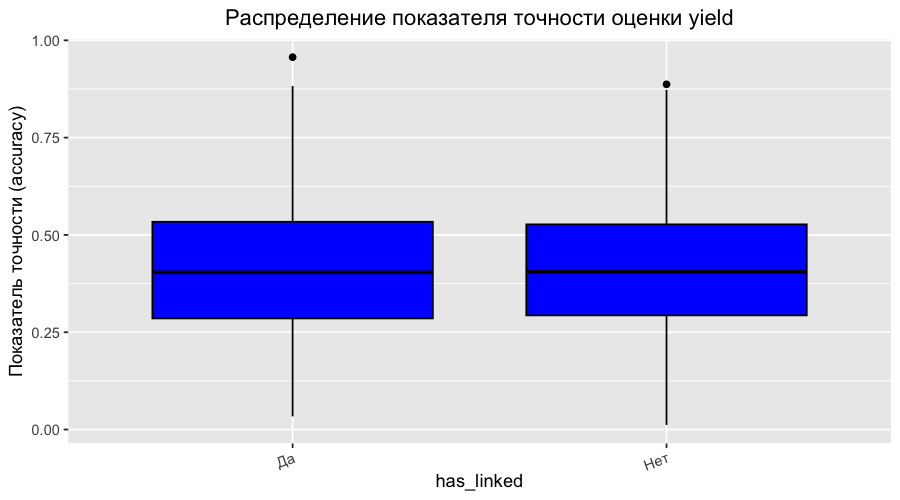

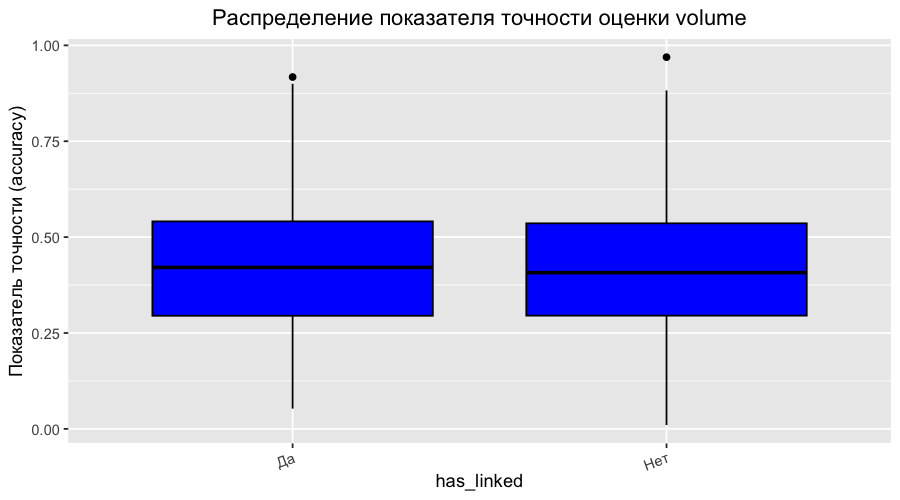

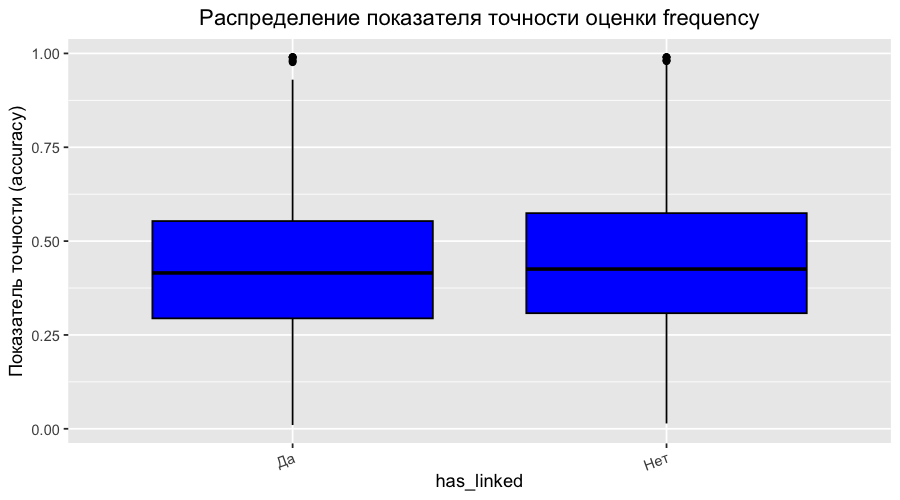

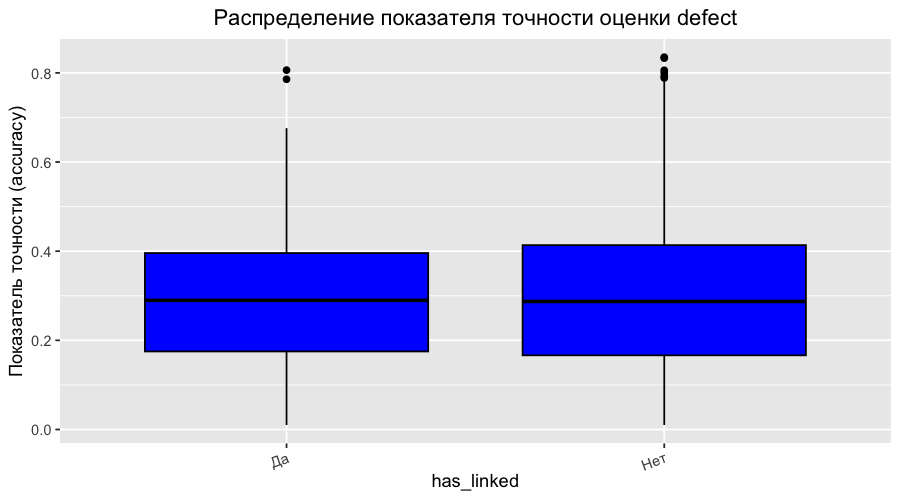

In [18]:
boxplot_distribution(dataset_unmeasured_linked(dataset, 'output', measured_output), 'has_linked', 'output')
boxplot_distribution(dataset_unmeasured_linked(dataset, 'related', measured_related), 'has_linked', 'related')
boxplot_distribution(dataset_unmeasured_linked(dataset, 'yield', measured_yield), 'has_linked', 'yield')
boxplot_distribution(dataset_unmeasured_linked(dataset, 'volume', measured_volume), 'has_linked', 'volume')
boxplot_distribution(dataset_unmeasured_linked(dataset, 'frequency', measured_frequency), 'has_linked', 'frequency')
boxplot_distribution(dataset_unmeasured_linked(dataset, 'defect', measured_defect), 'has_linked', 'defect')


При расчёте оценок по браку не было изделий, чьи связанные позиции присутствовали бы в фактических измерениях. Факт наличия фактических измерений у связанных позиций оказывает влияние на точность прогнозной оценки, но несильное. Медиана, первые и третьи квартили выше у изделий, данные о связанных позициях которых присутствуют в измерениях. Интерквартильный размах у таких изделий меньше, чем у изделий, связанных позиций которых нет в измерениях. Но выбросы с высокими оценками есть как у изделий с фактическими измерениями у связанных позиций, так и без них.


### 2.3. Анализ точности оценок изделий без фактических измерений в зависимости от статуса сертификации

Статус сертификации также может влиять на точность оценки у изделий без фактических измерений.


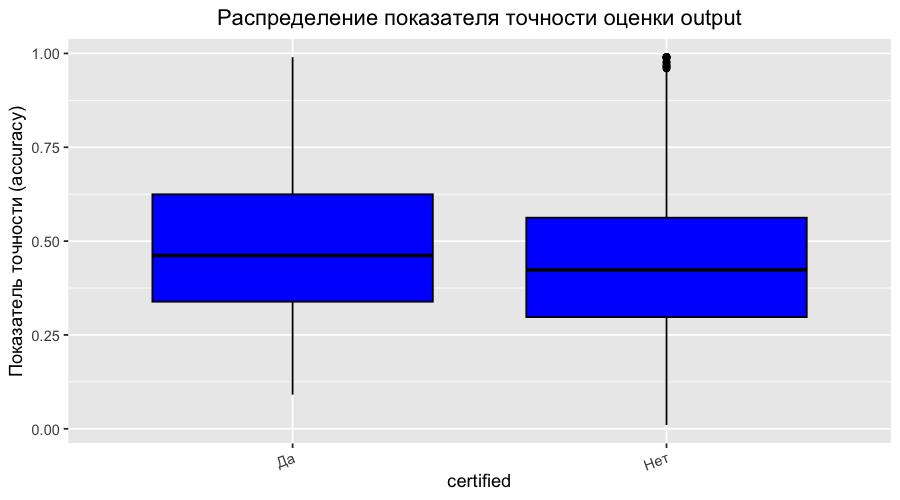

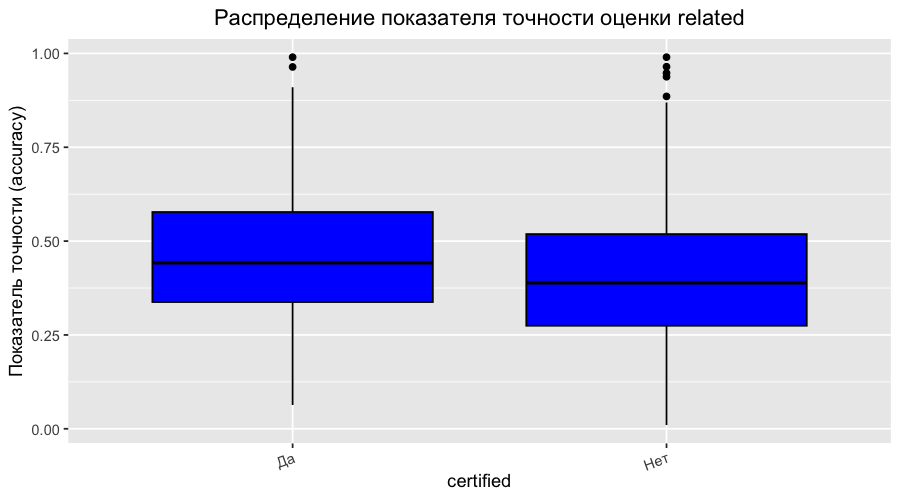

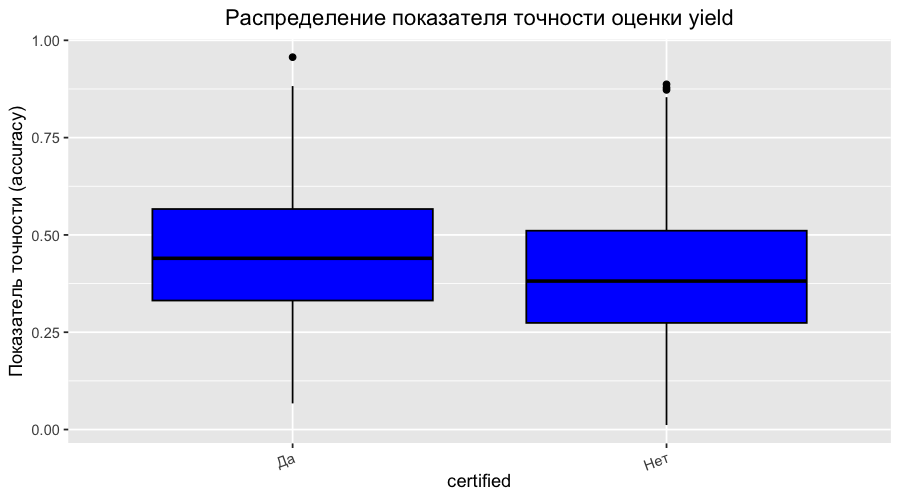

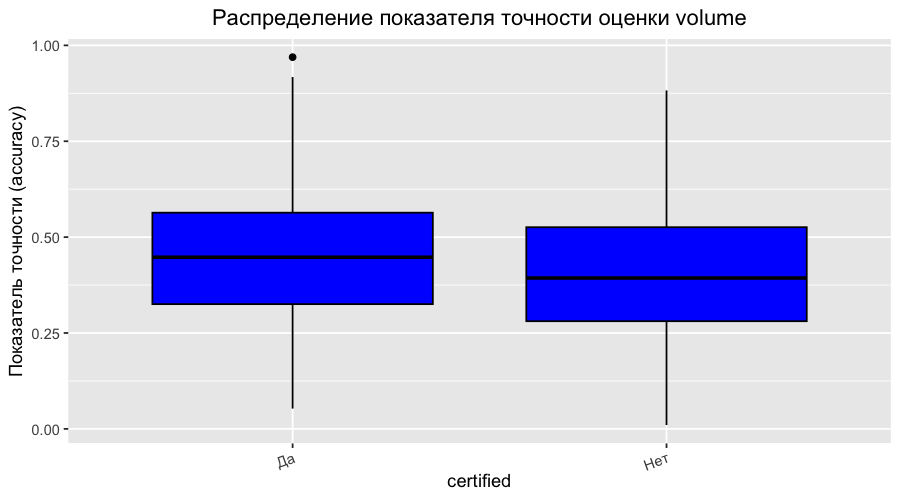

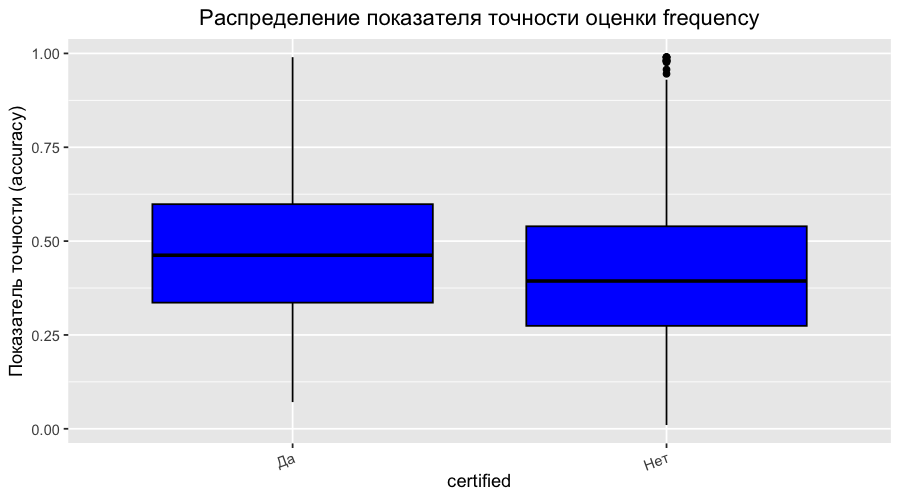

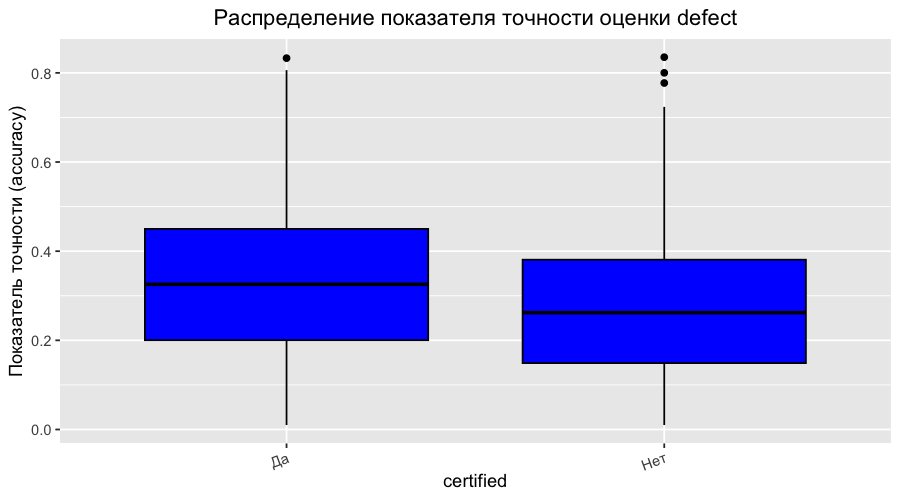

            output           related          yield            volume          
data        data.frame,23    data.frame,23    data.frame,23    data.frame,23   
layers      list,2           list,2           list,2           list,2          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     uneval,2         uneval,2         uneval,2         uneval,2        
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [19]:
sapply(metrics, function(x) {data = dataset_unmeasured(dataset, x); print(boxplot_distribution(data, 'certified', x))})


Несмотря на то, что общая точность полученных оценок невысока, мы можем наблюдать, что показатели точности оценок у сертифицированных изделий без измерений несколько выше, чем у несертифицированных. Существенно выше как медиана, первый и третий квартиль, так и интерквартильный размах. А вот диапазон выбросов как у сертифицированных, так и у несертифицированных изделий примерно одинаковый. Высокий показатель точности есть как у сертифицированных изделий, так и у несертифицированных.


### 2.4. Анализ точности оценок изделий без фактических измерений в зависимости от серии


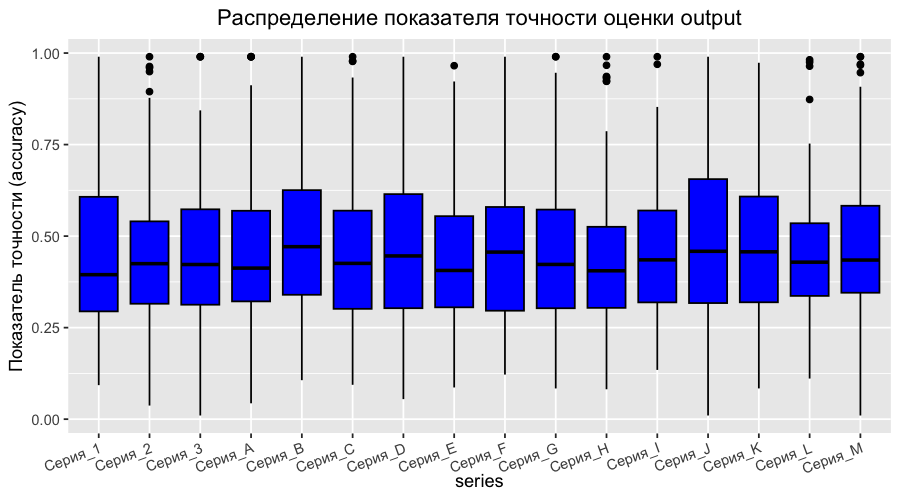

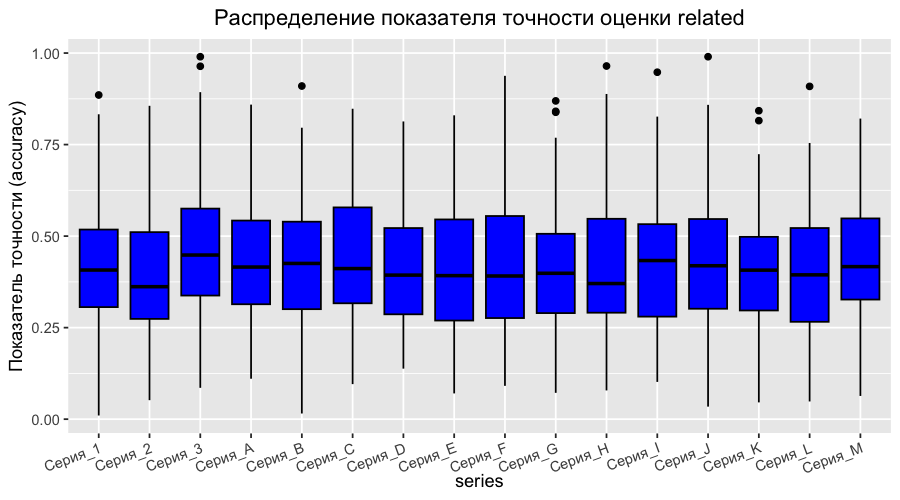

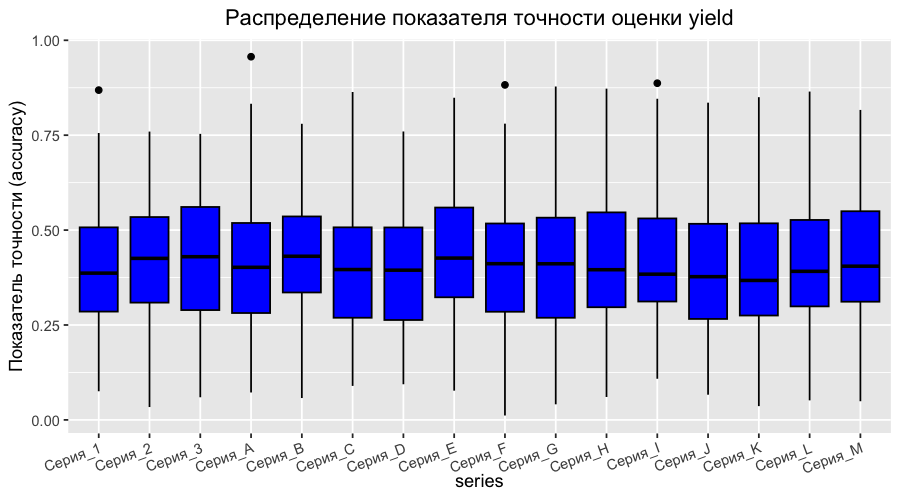

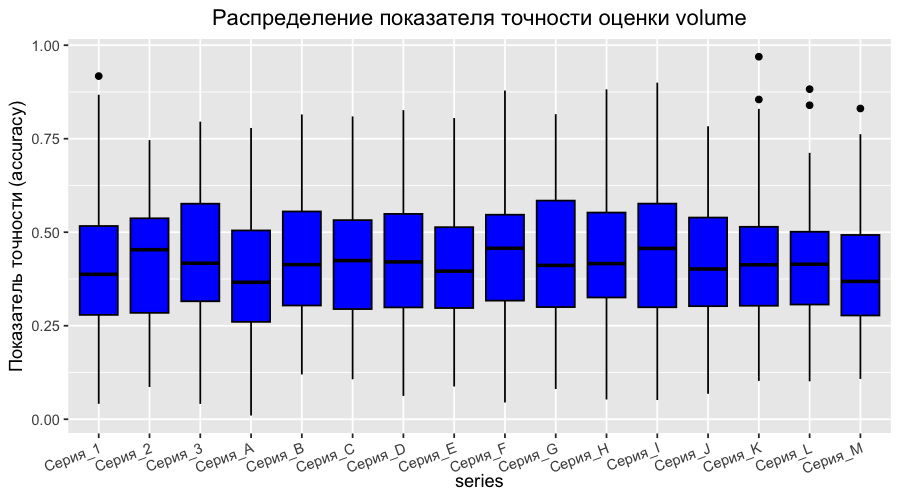

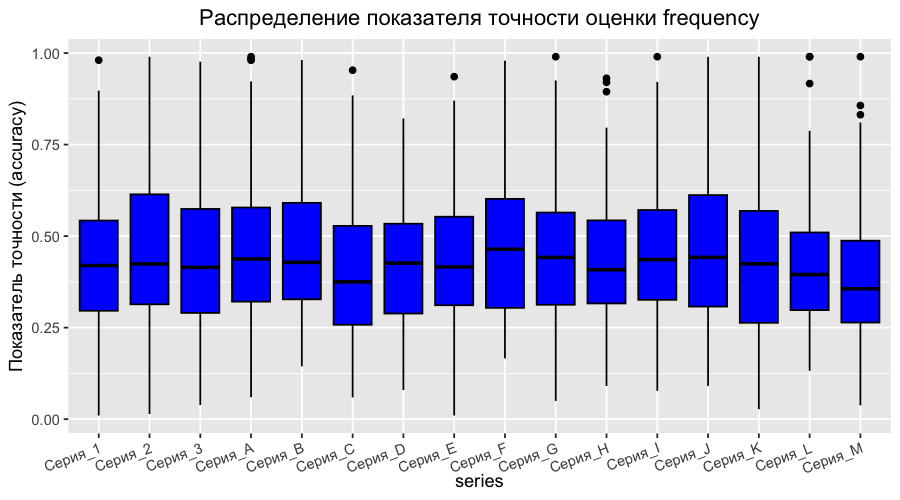

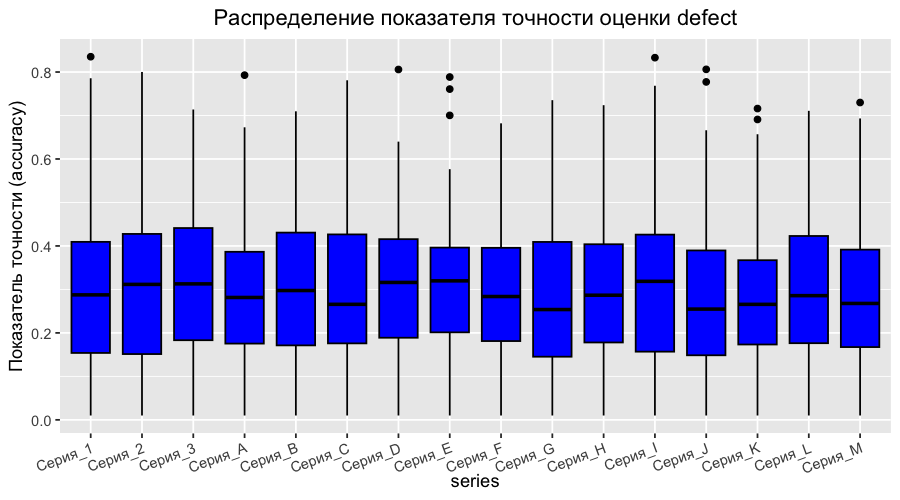

            output           related          yield            volume          
data        data.frame,23    data.frame,23    data.frame,23    data.frame,23   
layers      list,2           list,2           list,2           list,2          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     uneval,2         uneval,2         uneval,2         uneval,2        
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [20]:
sapply(metrics, function(x) {data = dataset_unmeasured(dataset, x); print(boxplot_distribution(data, 'series', x))})


К сожалению, ни у одной из серий таких изделий медиана не проходит выше показателя точности 0.4, третий квантиль не проходит выше показателя 0.5. У некоторых серий присутствуют выбросы, и показатель может достигать значения 0.8 и выше, но это, скорее, единичные случаи.


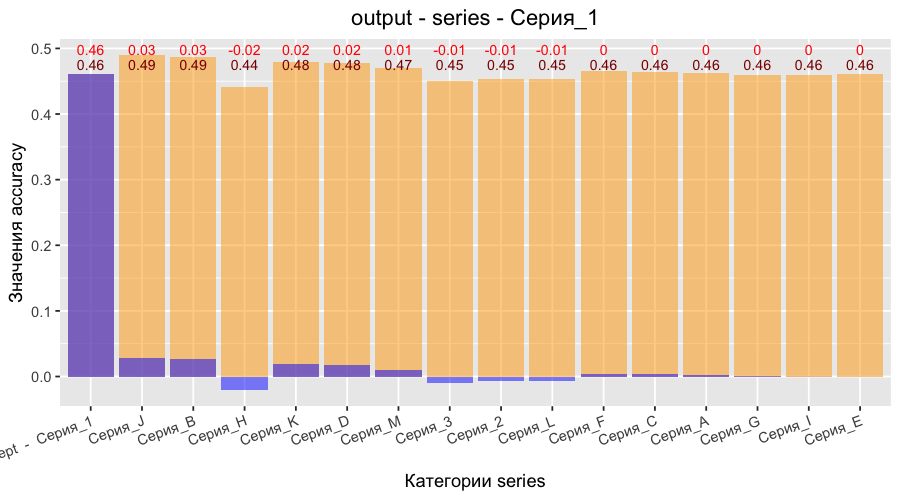

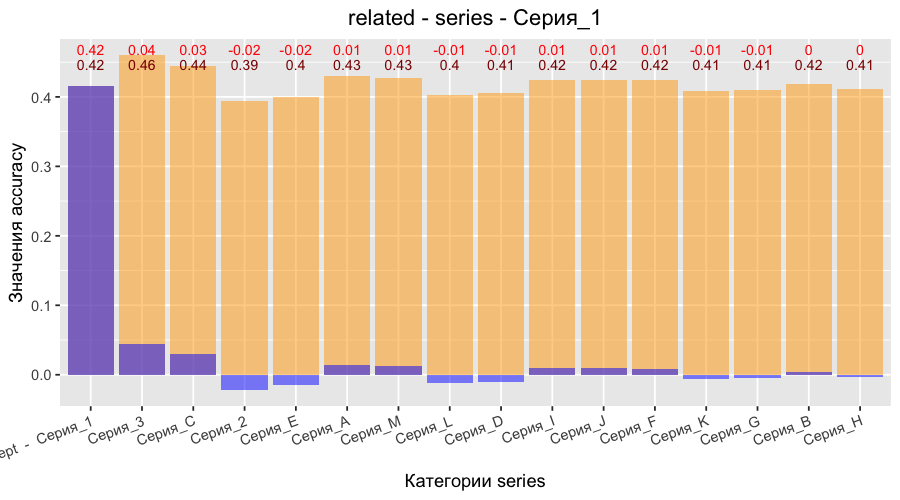

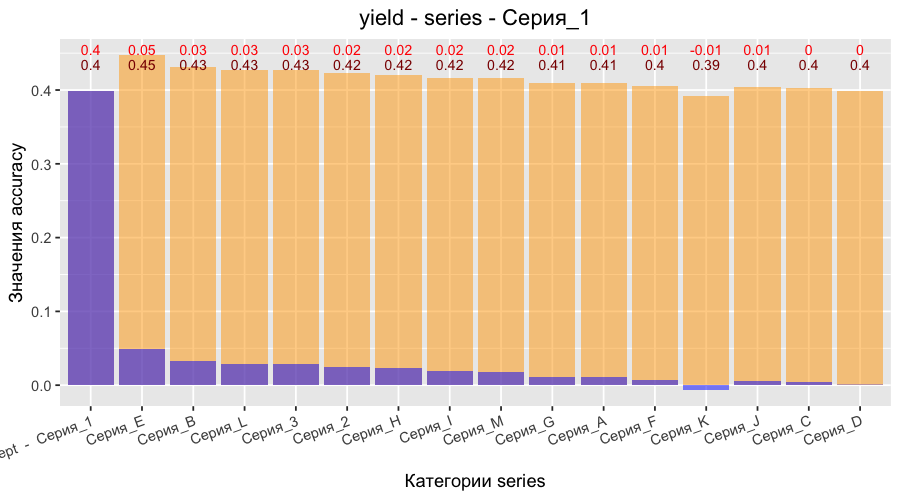

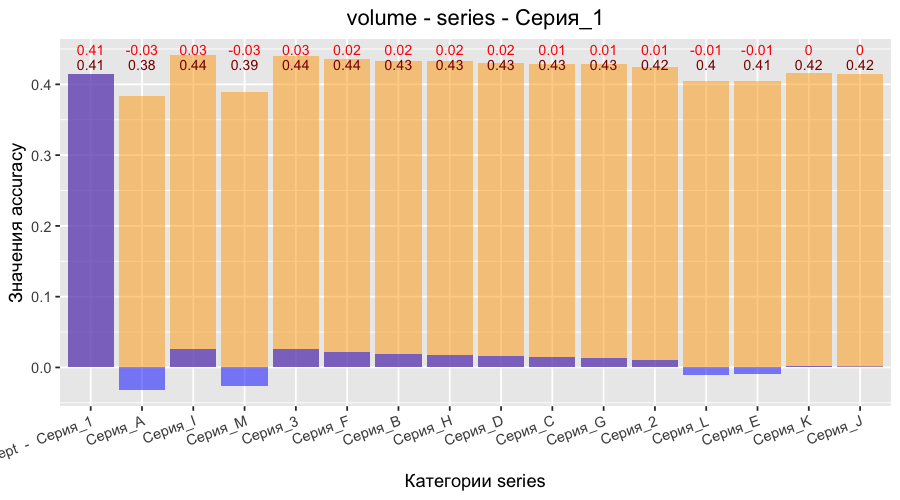

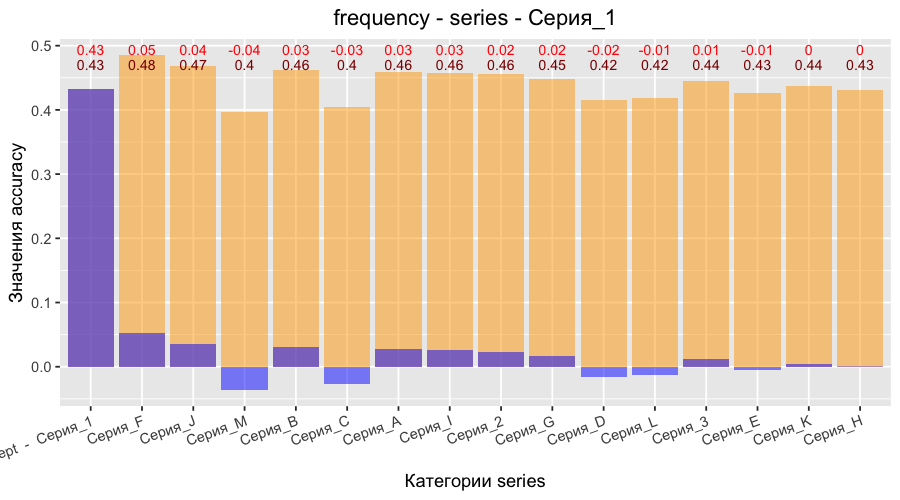

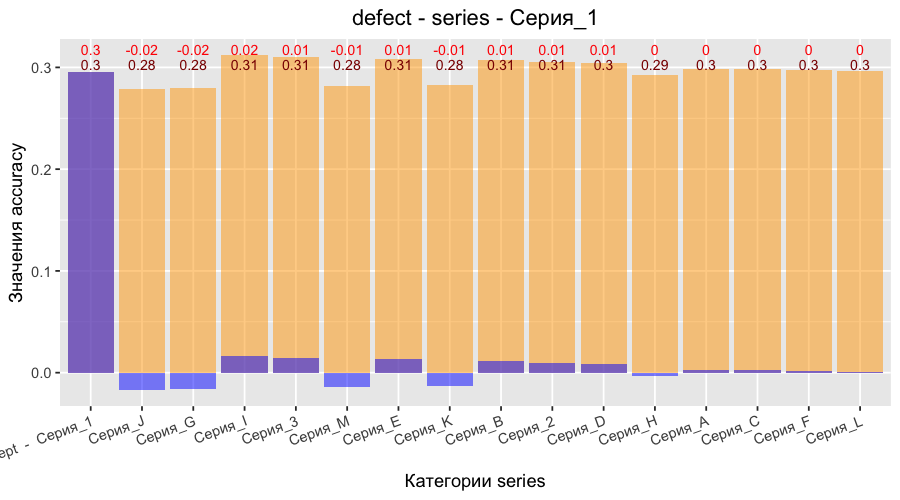

            output           related          yield            volume          
data        data.frame,4     data.frame,4     data.frame,4     data.frame,4    
layers      list,4           list,4           list,4           list,4          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     ~features        ~features        ~features        ~features       
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [21]:
sapply(metrics, function(x) {print(linear_model_cat(dataset_unmeasured(dataset, x), x, 'series', 'Серия_1'))})


При проведении регрессионного анализа точности оценок в зависимости от серии изделия за основу мы взяли Серию_1. Поскольку здесь находятся изделия, данных о которых нет в измерениях, показатели точности здесь невысокие. Средний показатель у этой серии составляет 0.33. Наилучшие показатели, если можно так говорить, у следующих серий: Серия_N, Серия_A, Серия_O, Серия_E. Наихудшие показатели получились у серий Серия_H, Серия_L, Серия_P, Серия_Q, Серия_K. 

### 2.5. Анализ точности оценок изделий без фактических измерений в зависимости от года выпуска


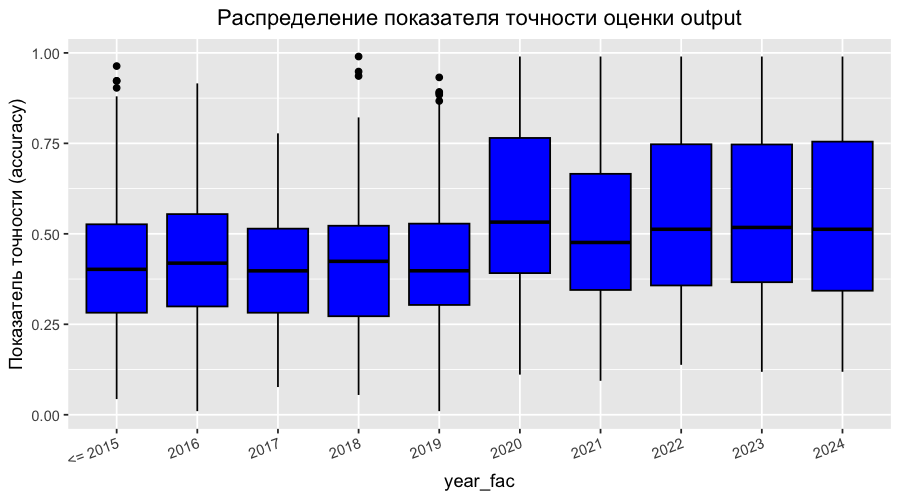

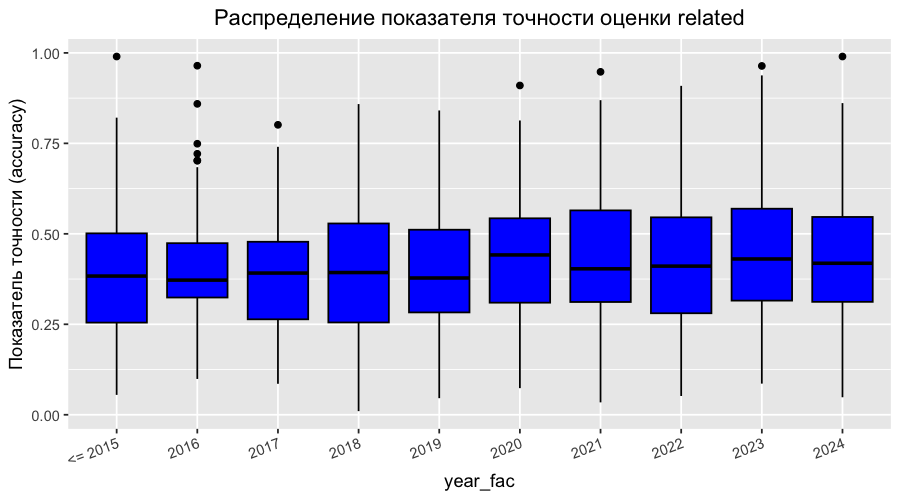

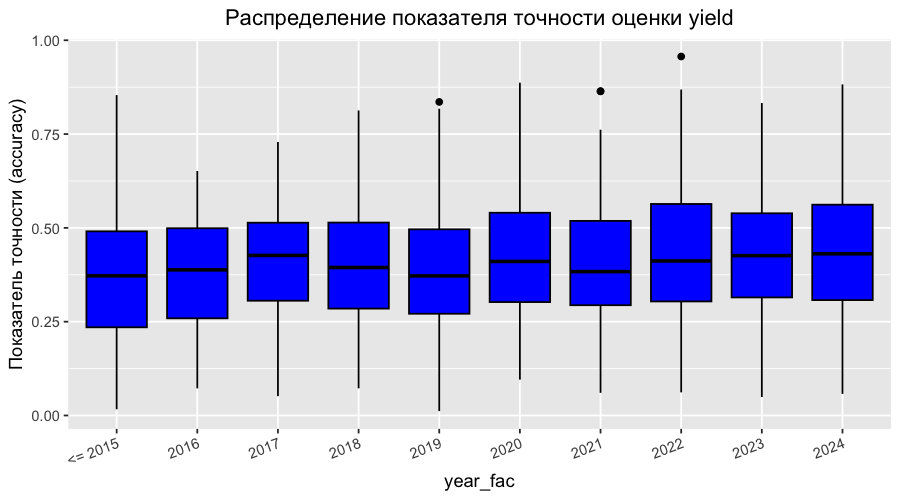

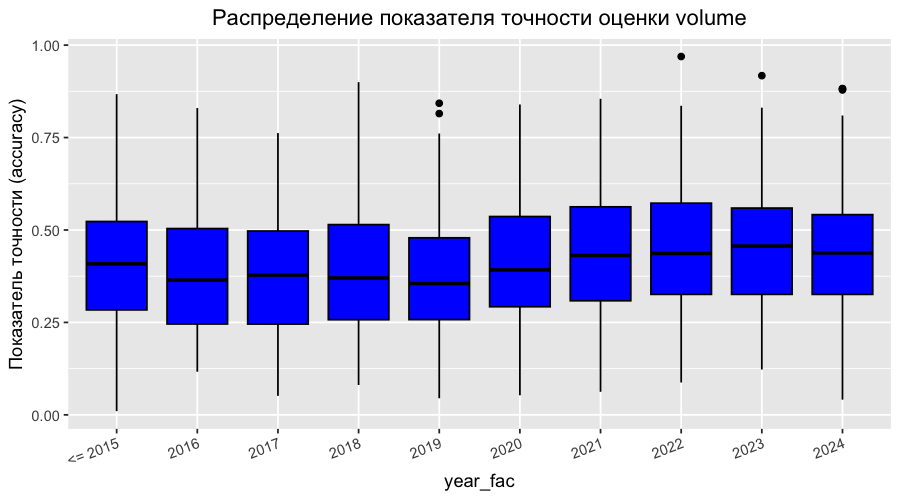

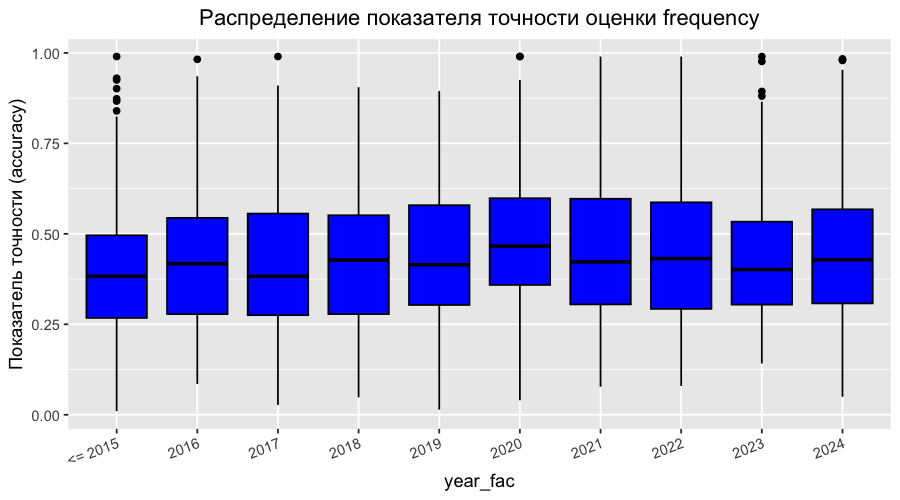

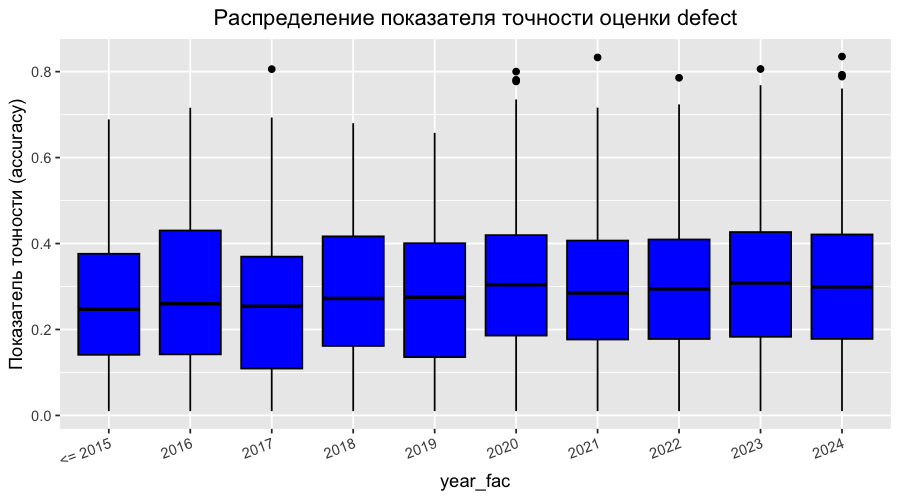

            output           related          yield            volume          
data        data.frame,23    data.frame,23    data.frame,23    data.frame,23   
layers      list,2           list,2           list,2           list,2          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     uneval,2         uneval,2         uneval,2         uneval,2        
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [22]:
sapply(metrics, function(x) {data = dataset_unmeasured(dataset, x); print(boxplot_distribution(data, 'year_fac', x))})


Здесь также общая точность полученных оценок не высока. В подавляющем большинстве медианы и третьи квартили не достигают показателя даже 0.5. Тем не менее есть показатели точности оценок со значениями 0.8 и выше, которые зафиксированы в качестве выбросов. Отдельно следует отметить показатели точности в расчёте оценок производительности у изделий 2023 - 2024 гг. выпуска. У изделий 2023 года выпуска медиана меньше 0.5, но третий квартиль на достаточно высоком уровне - > 0.75.


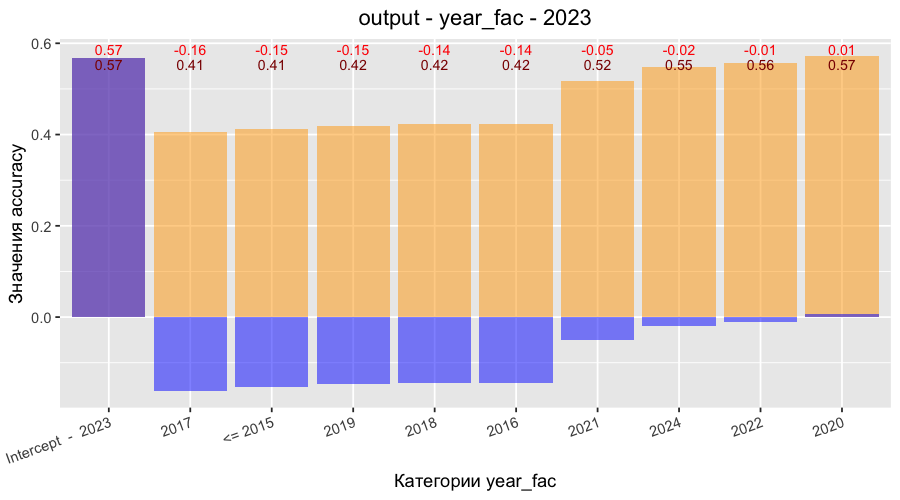

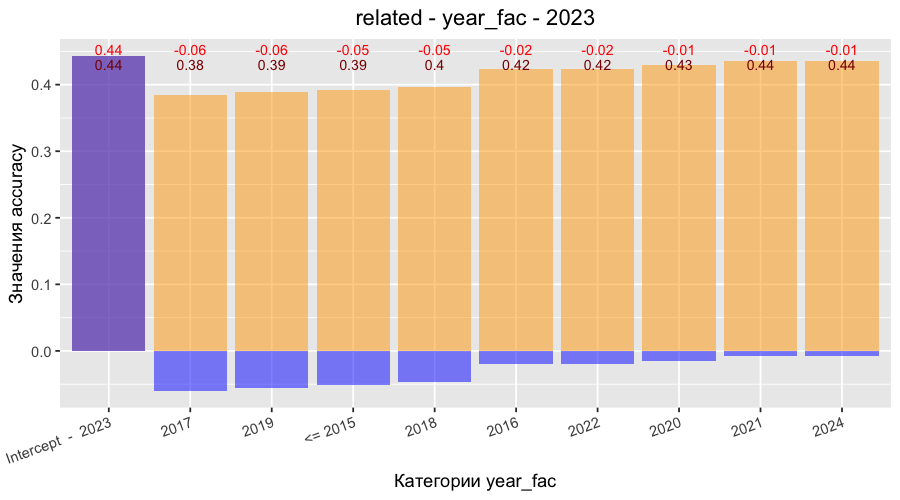

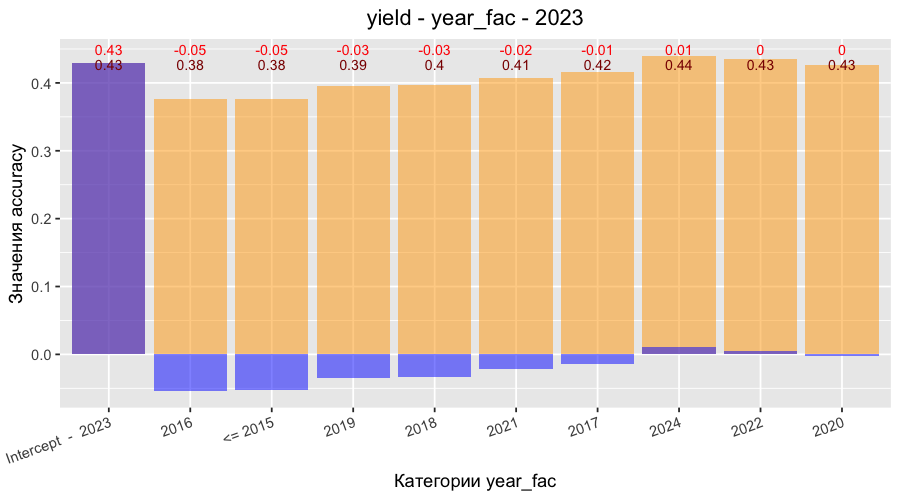

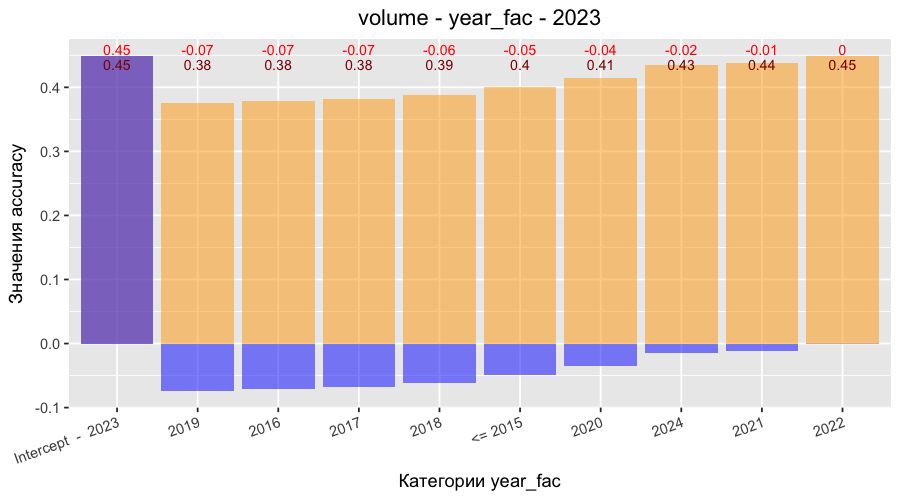

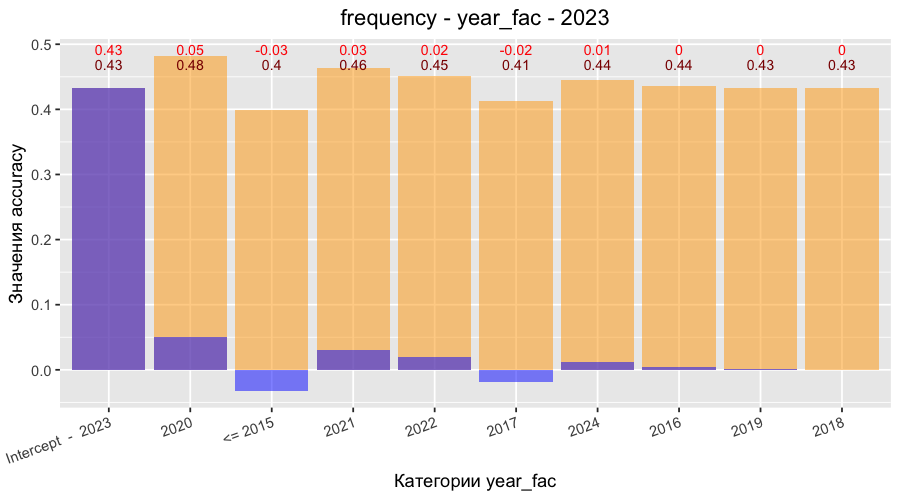

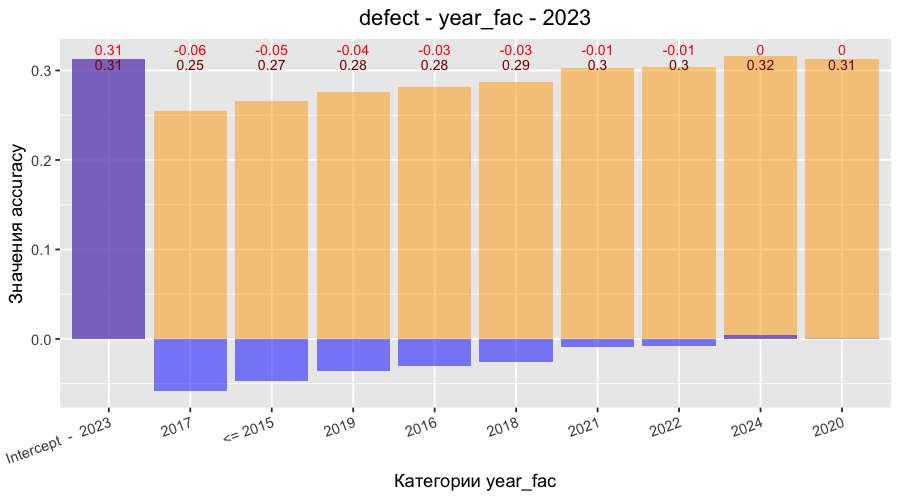

            output           related          yield            volume          
data        data.frame,4     data.frame,4     data.frame,4     data.frame,4    
layers      list,4           list,4           list,4           list,4          
scales      ScalesList,2     ScalesList,2     ScalesList,2     ScalesList,2    
guides      Guides,2         Guides,2         Guides,2         Guides,2        
mapping     ~features        ~features        ~features        ~features       
theme       list,2           list,2           list,2           list,2          
coordinates CoordCartesian,5 CoordCartesian,5 CoordCartesian,5 CoordCartesian,5
facet       FacetNull,2      FacetNull,2      FacetNull,2      FacetNull,2     
plot_env    ?                ?                ?                ?               
layout      Layout,1         Layout,1         Layout,1         Layout,1        
labels      list,4           list,4           list,4           list,4          
            frequency        defect     

In [23]:
sapply(metrics, function(x) {print(linear_model_cat(dataset_unmeasured(dataset, x), x, 'year_fac', '2023'))})


А при проведении регрессионного анализа точности оценок в зависимости от года за основу мы взяли год выпуска 2023. Здесь также мы рассматриваем изделия без измерений. Средний показатель у этого года составляет 0.44. Неожиданно хороший показатель точности у изделий без измерений 2024 года выпуска. Это говорит о хорошем качестве таких данных. 

# 3. Заключение
На основании полученных оценок точность прогнозной оценки изделия напрямую зависит от наличия данных этих изделий в фактических измерениях. Наличие этих данных гарантирует точность оценки от 0.8. Связанные позиции и лабораторные данные в этом случае играют уже второстепенную роль, они незначительно повышают точность этой оценки.

После расчёта оценок необходимо отфильтровать оценки с точностью свыше 0.8 (или ещё выше). В дальнейшем оставшиеся оценки можно рассчитать с помощью уточняющей модели. Наличие уже готовых качественных оценок позволит увеличить качество остальных. Оценки по лабораторным данным стоит рассчитать отдельно с помощью лабораторной модели. Оценки, рассчитанные именно по лабораторным данным, будут точнее оценок, чем рассчитанные с помощью основной модели.

В данный момент мы можем полностью доверять тем оценкам, которые были рассчитаны с использованием фактических измерений. Для того, чтобы доверять оценкам изделия, у которого нет фактических измерений, необходима дальнейшая работа.
